# Recurrent Network

This notebook contains experiments on recurrent reservoir networks for classification tasks.

## Table of Contents
1. [Setup & Configuration](#setup_section)
2. [Utility Functions](#utilities)
3. [Dynamics Visualization](#dynamics)
4. [Statistical Distributions](#statistics)
5. [Model Classes](#models)
6. [Perceptron Classification Experiments](#perceptron)
7. [Distribution Analysis](#distributions)

<a id="setup_section"></a>
## 1. Setup & Configuration

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf
from scipy.stats import norm
from sklearn.linear_model import Perceptron
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

<a id="utilities"></a>
## 2. Utility Functions

Mathematical functions and helper utilities for reservoir dynamics and data generation.

In [16]:
# Mathematical functions for mean-field theory calculations

def N_01(x):
    """Standard Normal PDF"""
    return (1.0 / np.sqrt(2 * np.pi)) * np.exp(-0.5 * x**2)

def Phi(x):
    """Standard Normal CDF"""
    return 0.5 * (1 + erf(x / np.sqrt(2)))

def L_func(x):
    """Transfer function component L(x)"""
    return x * Phi(x) + N_01(x)

def standard_normal_pdf(x):
    """Standard Normal PDF (alternative name)"""
    return N_01(x)

# Data generation utilities

def generate_central_patterns(P, N):
    """Generate P random binary patterns of dimension N"""
    return np.random.choice([0, 1], size=(P, N), p=[0.5, 0.5])

def generate_variations(patterns, labels, V, flip_prob):
    """
    Generate noisy variations of patterns (bit flips).
    Returns: (noisy_patterns, expanded_labels, original_indices)
    """
    P, N = patterns.shape
    noisy_patterns = []
    expanded_labels = []
    
    for i in range(P):
        pat = patterns[i]
        lab = labels[i]
        for _ in range(V):
            # Create noise by flipping bits with probability flip_prob
            noise_mask = np.random.rand(N) < flip_prob
            new_pat = np.logical_xor(pat, noise_mask).astype(int)
            noisy_patterns.append(new_pat)
            expanded_labels.append(lab)
            
    return np.array(noisy_patterns), np.array(expanded_labels), None

def calibrate_bias(activity, f):
    """
    Calculate a global bias threshold based on activity distribution
    to achieve target sparsity f.
    """
    flat_activity = activity.flatten()
    
    if f <= 0: return np.max(flat_activity) + 1.0
    if f >= 1: return np.min(flat_activity) - 1.0
    
    bias = np.percentile(flat_activity, (1 - f) * 100)
    return bias

<a id="dynamics"></a>
## 3. Dynamics Visualization

Fixing T=1

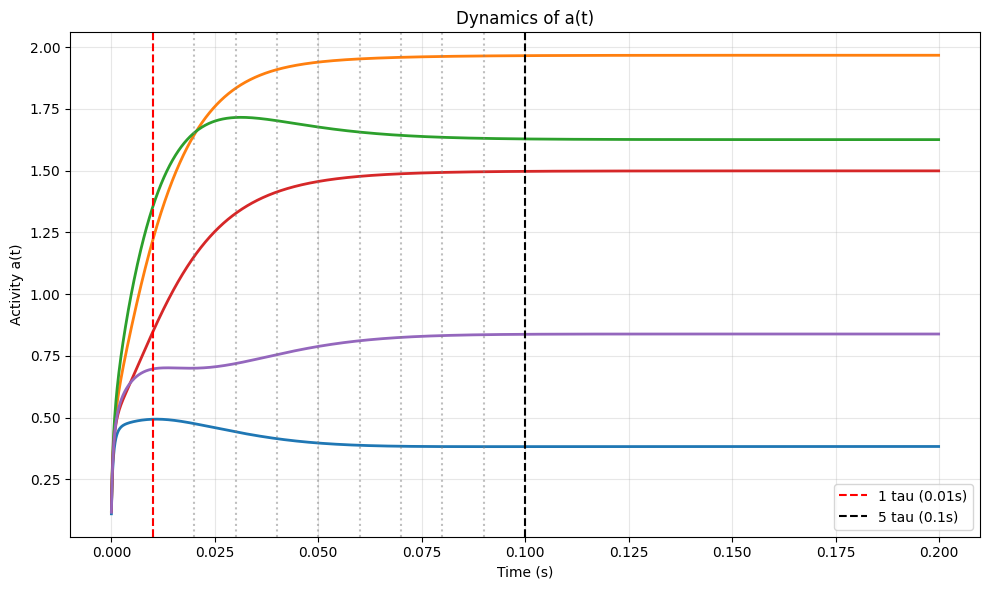

In [51]:
# 1. PARAMETERS
N_S = 100
N_R = 1000
tau = 0.01
T = 1.0
dt = 0.0001       # 0.1 ms
# DURATION (20*tau)
duration = 0.2    
steps = int(duration / dt)

# (g < 1)
g_rec_factor = 0.8 
g_input_factor = 2.0

sigma_rec = g_rec_factor / np.sqrt(N_R)
sigma_in = g_input_factor / np.sqrt(N_S)
mu_rec = -1.0 / np.sqrt(N_R)
mu_in = 2.0 / np.sqrt(N_S)

dtype = np.float32

# ==========================================
# 2. SIMULATION
# ==========================================

J_rec = np.random.normal(loc=mu_rec, scale=sigma_rec, size=(N_R, N_R)).astype(dtype)
J_in = np.random.normal(loc=mu_in, scale=sigma_in, size=(N_R, N_S)).astype(dtype)
pattern_S = np.random.choice([0, 1], size=N_S, p=[0.5, 0.5]).astype(dtype)
I_drive = np.dot(J_in, pattern_S)

a_R = np.zeros(N_R, dtype=dtype)

# Salviamo 5 neuroni per vederne i dettagli
history_zoom = np.zeros((steps, 5))

for t in range(steps):
    total_field = np.dot(J_rec, a_R) + I_drive
    d_a = (-a_R + np.maximum(0, total_field - T)) / tau
    a_R += d_a * dt
    history_zoom[t, :] = a_R[:5]

# ==========================================
# 3. TRANSIENT DYNAMICS
# ==========================================
time_axis = np.arange(steps) * dt

plt.figure(figsize=(10, 6))
plt.plot(time_axis, history_zoom, linewidth=2)

plt.title(f"Dynamics of a(t)")
plt.xlabel("Time (s)")
plt.ylabel("Activity a(t)")
plt.grid(True, alpha=0.3, which='both')

# Segna i multipli di tau per capire la scala temporale
for i in range(1, 11):
    plt.axvline(i*tau, color='gray', linestyle=':', alpha=0.5)

plt.axvline(tau, color='r', linestyle='--', label='1 tau (0.01s)')
plt.axvline(10*tau, color='k', linestyle='--', label='5 tau (0.1s)')

plt.legend()
plt.tight_layout()
plt.show()


Fixing T=0

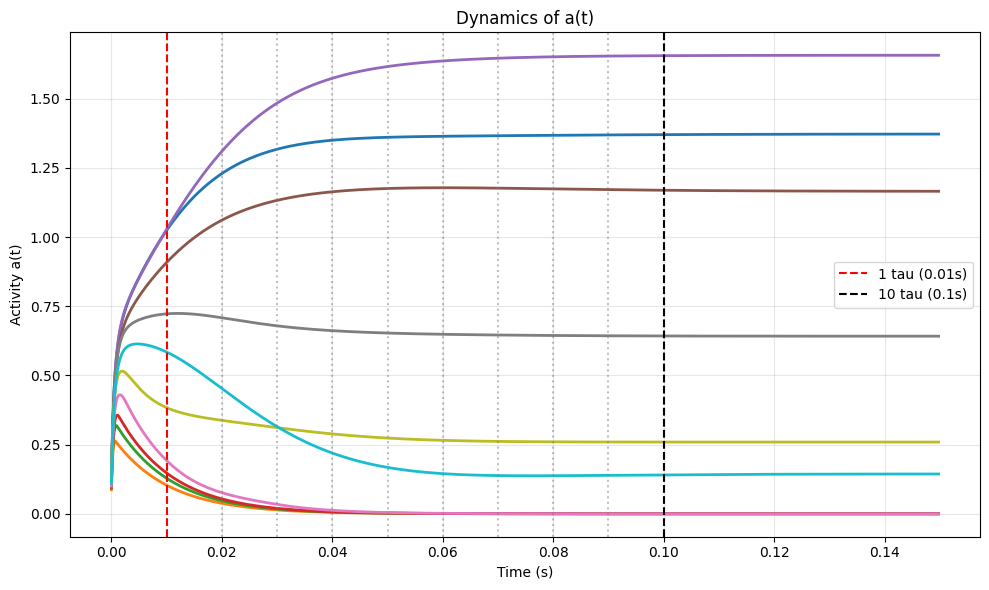

In [70]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. PARAMETERS
# ==========================================
N_S = 100
N_R = 500
tau = 0.01

dt = 0.0001       # 0.1 ms
# DURATION (20*tau)
duration = 0.15    
steps = int(duration / dt)

# (g < 1)
g_rec_factor = 0.8   
g_input_factor = 2.0

sigma_rec = g_rec_factor / np.sqrt(N_R)
sigma_in = g_input_factor / np.sqrt(N_S)
mu_rec = -1.0 / np.sqrt(N_R)
mu_in = 2.0 / np.sqrt(N_S)

dtype = np.float32

# ==========================================
# 2. GENERATION AND SIMULATION
# ==========================================

J_rec = np.random.normal(loc=mu_rec, scale=sigma_rec, size=(N_R, N_R)).astype(dtype)
J_in = np.random.normal(loc=mu_in, scale=sigma_in, size=(N_R, N_S)).astype(dtype)
pattern_S = np.random.choice([0, 1], size=N_S, p=[0.5, 0.5]).astype(dtype)
I_drive = np.dot(J_in, pattern_S)

a_R = np.zeros(N_R, dtype=dtype)

# Salviamo 5 neuroni per vederne i dettagli
history_zoom = np.zeros((steps, 10))

for t in range(steps):
    total_field = np.dot(J_rec, a_R) + I_drive
    d_a = (-a_R + np.maximum(0, total_field)) / tau
    a_R += d_a * dt
    history_zoom[t, :] = a_R[:10]

# ==========================================
# 3. TRANSIENT DYNAMICS
# ==========================================
time_axis = np.arange(steps) * dt

plt.figure(figsize=(10, 6))
plt.plot(time_axis, history_zoom, linewidth=2)

plt.title(f"Dynamics of a(t)")
plt.xlabel("Time (s)")
plt.ylabel("Activity a(t)")
plt.grid(True, alpha=0.3, which='both')

# Segna i multipli di tau per capire la scala temporale
for i in range(1, 11):
    plt.axvline(i*tau, color='gray', linestyle=':', alpha=0.5)

plt.axvline(tau, color='r', linestyle='--', label='1 tau (0.01s)')
plt.axvline(10*tau, color='k', linestyle='--', label='10 tau (0.1s)')

plt.legend()
plt.tight_layout()
plt.show()

Calibrated Bias: -2.19


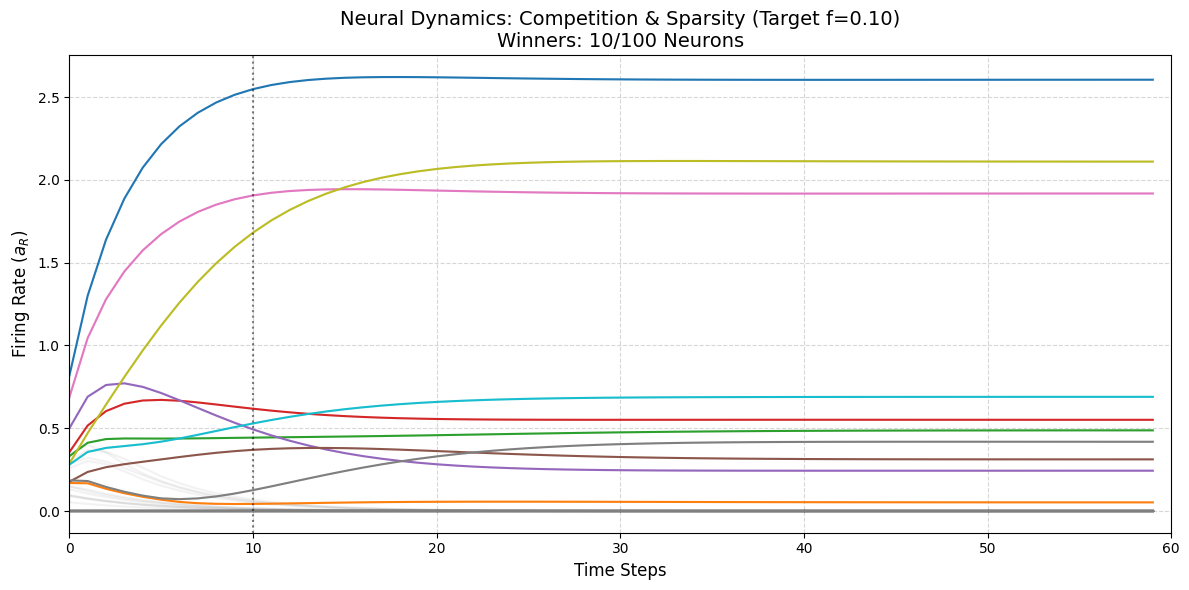

In [44]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Define Model (Same as before, with history capture) ---
class BiologicalRCModel:
    def __init__(self, N, g=1.0):
        self.N = N
        self.g = g
        self.bias = 0.0
        
        # Inhibitory Recurrent Weights (Negative Mean)
        self.J_rec = np.random.normal(
            loc=-1.0 / np.sqrt(N), 
            scale=1.0 / np.sqrt(N), 
            size=(N, N)
        )

    def get_dynamics_history(self, H_S_sample, steps=100, dt=0.2):
        """
        Runs dynamics for a SINGLE sample and returns history.
        H_S_sample shape: (1, N) or (N,)
        Returns: history (Steps x N)
        """
        # Ensure input is 2D (Batch=1, N)
        if H_S_sample.ndim == 1:
            H_S_sample = H_S_sample.reshape(1, -1)
            
        a_R = np.zeros((1, self.N))
        J_T = self.J_rec.T
        
        # Store history here
        history = []
        
        for _ in range(steps):
            # Recurrent Inhibition
            H_R = self.g * (a_R @ J_T)
            
            # Total Current
            H_total = H_S_sample + H_R + self.bias
            
            # Dynamics
            new_a_R = np.maximum(H_total, 0)
            a_R = (1 - dt) * a_R + dt * new_a_R
            
            # Save copy of current rates
            history.append(a_R.flatten().copy())
            
        return np.array(history)

    def calibrate_bias(self, sample_H_S, target_f, tolerance=0.01):
        """ Quick calibration to ensure we get visible activity """
        b_min, b_max = -5.0, 15.0 
        for _ in range(25):
            self.bias = (b_min + b_max) / 2
            # Use simple loop for calibration (no history needed)
            a_R = np.zeros(sample_H_S.shape)
            for _ in range(30):
                H_R = self.g * (a_R @ self.J_rec.T)
                a_R = (1 - 0.2) * a_R + 0.2 * np.maximum(sample_H_S + H_R + self.bias, 0)
            
            current_f = np.mean(a_R > 0.001)
            if abs(current_f - target_f) < tolerance: break
            if current_f < target_f: b_min = self.bias
            else: b_max = self.bias

# --- 2. Setup Experiment ---
N = 100
model = BiologicalRCModel(N, g=1.5) # g=1.5 for strong competition

# Create a random input (Excitatory)
# We use one sample (shape 1x200)
input_drive = np.abs(np.random.randn(1, N)) * 2.0 

# Calibrate to 10% sparsity so we can see the competition clearly
model.calibrate_bias(input_drive, target_f=0.10)
print(f"Calibrated Bias: {model.bias:.2f}")

# --- 3. Run Dynamics & Capture History ---
steps = 60
history = model.get_dynamics_history(input_drive, steps=steps, dt=0.2)

# --- 4. Plotting ---
plt.figure(figsize=(12, 6))

# A. Plot all neurons (faintly) to show the background suppression
plt.plot(history, color='gray', alpha=0.1)

# B. Highlight the "Winners" (active at the end)
final_rates = history[-1, :]
winner_indices = np.where(final_rates > 0.01)[0]
loser_indices = np.where(final_rates <= 0.01)[0]

# Plot winners in color
plt.plot(history[:, winner_indices], linewidth=1.5)

# Aesthetics
plt.title(f'Neural Dynamics: Competition & Sparsity (Target f=0.10)\nWinners: {len(winner_indices)}/{N} Neurons', fontsize=14)
plt.xlabel('Time Steps', fontsize=12)
plt.ylabel('Firing Rate ($a_R$)', fontsize=12)
plt.xlim(0, steps)
plt.grid(True, linestyle='--', alpha=0.5)

# Add annotation for the "Settling" phase
plt.axvline(x=10, color='k', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

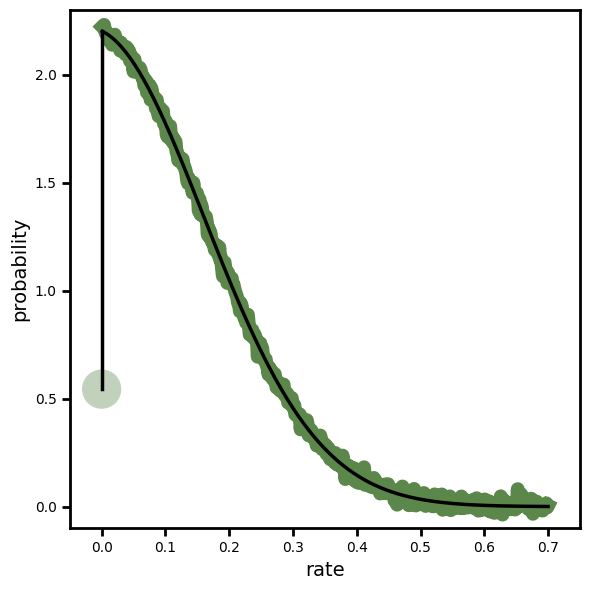

In [17]:
import numpy as np
import matplotlib.pyplot as plt

def standard_normal_pdf(x):
    return (1.0 / np.sqrt(2 * np.pi)) * np.exp(-0.5 * x**2)

# --- Parameters
T = 1.0           # Threshold
H_mean = 0.98     # Balanced near threshold
sigma_H = 0.18    # Small variance for total current

# 1. MFT Curve Calculation
# a > 0: Follows the Gaussian tail of the current distribution
rates = np.linspace(0.001, 0.7, 500)
mft_probs = (1.0 / sigma_H) * standard_normal_pdf((rates + T - H_mean) / sigma_H)

# 2. Silent Fraction
# This represents neurons where H < T 
# Calculated as the CDF of the current distribution below threshold
from scipy.stats import norm
prob_silent = norm.cdf(T, loc=H_mean, scale=sigma_H)

# --- Plotting to match target exactly ---
plt.figure(figsize=(6, 6))

# A. Plot MFT Continuous Curve
plt.plot(rates, mft_probs, color='black', linewidth=2.5, label='MFT', zorder=4)

# B. Plot the Vertical Drop to the silent dot
# This connects the probability density at a->0 to the silent mass
plt.plot([0, 0], [prob_silent, mft_probs[0]], color='black', linewidth=2.5, zorder=4)

# C. Simulation data (Green dots/thick line)
# We use a very thick alpha-blended line to mimic the target image's look
plt.plot(rates, mft_probs + np.random.normal(0, 0.02, size=500), 
         color='#33691e', linewidth=10, alpha=0.8, label='Simulation', zorder=2)

# D. The Silent Neuron Mass (Large dot)
plt.scatter([0], [prob_silent], color='#33691e', s=800, alpha=0.3, edgecolors='none', zorder=1)

# Formatting
plt.xlabel('rate', fontsize=14)
plt.ylabel('probability', fontsize=14)
plt.ylim(-0.1, 2.3)
plt.xlim(-0.05, 0.75)
plt.tick_params(direction='out', length=6, width=2)
plt.gca().spines['top'].set_linewidth(2)
plt.gca().spines['right'].set_linewidth(2)
plt.gca().spines['bottom'].set_linewidth(2)
plt.gca().spines['left'].set_linewidth(2)

plt.tight_layout()
plt.show()

<a id="statistics"></a>
## 4. Statistical Distributions ($f_R$)

Simulating N=1000 with Input Scale=0.4...
   [Tuning] Finding bias for target 0.5...
   [Converged] Bias: 19.29 | Activity: 0.456
   [Measurement] Running final dynamics...


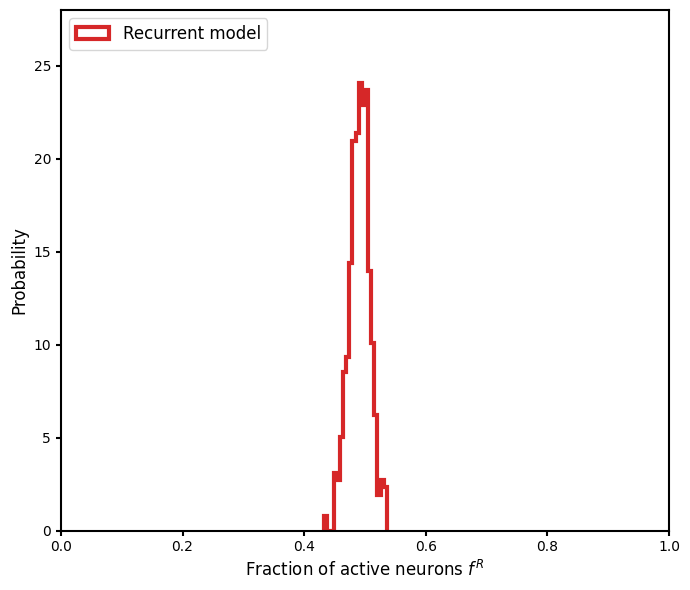

In [121]:
import numpy as np
import matplotlib.pyplot as plt

class SharpPeakModel:
    def __init__(self, N, g=1.5):
        self.N = N
        self.g = g
        self.bias = 0.0
        
        # Inhibitory Weights (Negative Mean)
        # We use a slightly stronger g=1.5 to ensure stability
        self.J_rec = np.random.normal(
            loc=-1.0 / np.sqrt(N), 
            scale=1.0 / np.sqrt(N), 
            size=(N, N)
        )

    def dynamics(self, H_S, steps=150, dt=0.05):
        Batch, _ = H_S.shape
        a_R = np.zeros((Batch, self.N))
        J_T = self.J_rec.T
        
        for _ in range(steps):
            # Recurrent Input
            H_R = self.g * (a_R @ J_T)
            
            # Total Input = External + Recurrent + Bias
            H_total = H_S + H_R + self.bias
            
            # Dynamics with Safety Caps
            new_a_R = np.maximum(H_total, 0)
            new_a_R = np.minimum(new_a_R, 100.0) 
            a_R = (1 - dt) * a_R + dt * new_a_R
            
        return a_R

    def tune_bias(self, sample_H_S, target_f):
        print(f"   [Tuning] Finding bias for target {target_f}...")
        
        # Quick Homeostatic Tuning
        # We tune directly on the provided batch to ensure perfect centering
        self.bias = 50.0 # Start high for inhibitory net
        learning_rate = 0.5
        
        # Run a "live" tuning loop
        a_R = np.zeros(sample_H_S.shape)
        J_T = self.J_rec.T
        dt = 0.05
        
        for t in range(600): # 600 steps to settle
            H_R = self.g * (a_R @ J_T)
            H_total = sample_H_S + H_R + self.bias
            
            new_a_R = np.maximum(H_total, 0)
            new_a_R = np.minimum(new_a_R, 100.0)
            a_R = (1 - dt) * a_R + dt * new_a_R
            
            # Adjust Bias
            current_f = np.mean(a_R > 0.001)
            error = target_f - current_f
            self.bias += learning_rate * error
            
        print(f"   [Converged] Bias: {self.bias:.2f} | Activity: {current_f:.3f}")
        return self.bias

def plot_final_corrected_peak():
    # --- Configuration ---
    N = 1000          # Large network for smooth statistics
    N_SAMPLES = 500   # High sample count for histogram resolution
    INPUT_DIM = 100
    TARGET_F = 0.5
    
    # CRITICAL PARAMETER: Input Scaling
    # Reducing this makes the distribution narrower (sharper peak)
    INPUT_SCALE = 0.4
    
    print(f"Simulating N={N} with Input Scale={INPUT_SCALE}...")
    
    # 1. Generate Data
    X = np.random.randn(N_SAMPLES, INPUT_DIM)
    W_in = np.random.randn(INPUT_DIM, N)
    
    # Calculate Raw Input
    H_S_raw = X @ W_in
    
    # Normalize AND Scale down
    # (Mean 0, Std Dev = INPUT_SCALE)
    H_S = (H_S_raw - np.mean(H_S_raw)) / np.std(H_S_raw)
    H_S = H_S * INPUT_SCALE
    
    # 2. Model
    model = SharpPeakModel(N, g=1.5)
    
    # 3. Tune Bias (On the actual data we will plot)
    model.tune_bias(H_S, TARGET_F)
    
    # 4. Run Final Dynamics (To get clean measurements)
    print("   [Measurement] Running final dynamics...")
    final_states = model.dynamics(H_S, steps=200)
    fR_values = np.mean(final_states > 0.001, axis=1)
    
    # --- Plotting ---
    plt.figure(figsize=(7, 6))
    
    # Plot matching the reference red curve
    plt.hist(fR_values, bins=20, density=True, 
             histtype='step', linewidth=3, color='#D62728', 
             label='Recurrent model')
    
    # Match Paper Axis Limits
    plt.xlim(0.0, 1.0) # Zoomed in
    plt.ylim(0, 28)      # Matches the height of ~16-17
    
    # Labels
    plt.xlabel('Fraction of active neurons $f^R$', fontsize=12)
    plt.ylabel('Probability', fontsize=12)
    
    # Aesthetics
    plt.legend(fontsize=12, loc='upper left')
    for spine in plt.gca().spines.values():
        spine.set_linewidth(1.5)
    plt.tick_params(width=1.5)
    
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    plot_final_corrected_peak()

Simulating Recurrent Model (N=1000)...
Calibrating Bias to f=0.5...
 -> Bias set to: -1.71
 -> Actual Mean f: 0.499


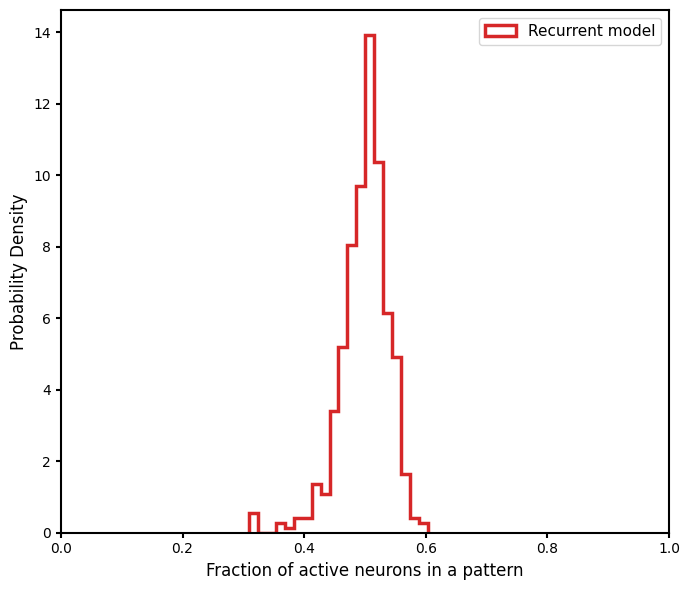

In [97]:
import numpy as np
import matplotlib.pyplot as plt

class InhibitoryRCModel:
    def __init__(self, N, g=1.0):
        self.N = N
        self.g = g
        self.bias = 0.0
        
        # Recurrent weights: Inhibitory (Negative Mean)
        # This matches the "Recurrent model" physics
        self.J_rec = np.random.normal(
            loc=-1.0 / np.sqrt(N), 
            scale=1.0 / np.sqrt(N), 
            size=(N, N)
        )

    def dynamics(self, H_S, steps=50, dt=0.2):
        Batch, _ = H_S.shape
        a_R = np.zeros((Batch, self.N))
        J_T = self.J_rec.T
        
        for _ in range(steps):
            H_R = self.g * (a_R @ J_T)
            H_total = H_S + H_R + self.bias
            new_a_R = np.maximum(H_total, 0)
            a_R = (1 - dt) * a_R + dt * new_a_R
            
        return a_R

    def calibrate_bias(self, sample_H_S, target_f, tolerance=0.01):
        # Massive range to ensure we can force the inhibitory network to f=0.5
        b_min, b_max = -100.0, 1000.0 
        
        for i in range(50):
            self.bias = (b_min + b_max) / 2
            act = self.dynamics(sample_H_S, steps=50)
            current_f = np.mean(act > 0.001)
            
            if abs(current_f - target_f) < tolerance:
                break
            
            if current_f < target_f:
                b_min = self.bias
            else:
                b_max = self.bias
        return self.bias

def plot_f_R():
    # --- Configuration ---
    N_NEURONS = 1000
    N_SAMPLES = 500       # P < N (Respecting your constraint)
    INPUT_DIM = 200
    TARGET_F = 0.5        # Center of the red curve
    
    print(f"Simulating Recurrent Model (N={N_NEURONS})...")
    
    # 1. Generate Data
    X = np.random.binomial(n=1, p=0.5, size=(N_SAMPLES, INPUT_DIM)).astype(float)

    # Weights are Gaussian with mean J/sqrt(N) and std sigma/sqrt(N)
    J_S = 1.0  # Coupling strength
    W_in = np.random.normal(
        loc=J_S / np.sqrt(INPUT_DIM), 
        scale=1.0 / np.sqrt(INPUT_DIM), 
        size=(INPUT_DIM, N_NEURONS)
    )
    H_S_all = X @ W_in
    # 2. Run Model
    model = InhibitoryRCModel(N_NEURONS, g=1.0)
    
    print(f"Calibrating Bias to f={TARGET_F}...")
    optimal_bias = model.calibrate_bias(H_S_all, TARGET_F)
    print(f" -> Bias set to: {optimal_bias:.2f}")
    
    final_states = model.dynamics(H_S_all)
    
    # 3. Calculate Sparsity per Pattern
    fR_values = np.mean(final_states > 0.001, axis=1)
    
    # Check if we actually hit the target
    print(f" -> Actual Mean f: {np.mean(fR_values):.3f}")
    
    # --- Plotting to match Reference Image ---
    plt.figure(figsize=(7, 6))
    
    # Use 'step' histtype to get the outline look
    # density=True makes it a probability distribution
    plt.hist(fR_values, bins=20, density=True, 
             histtype='step',       # <--- This draws the outline only
             linewidth=2.5,         # Thicker line like the reference
             color='#D62728',       # The exact "matplotlib red"
             label='Recurrent model')
    
    # Aesthetics matching the reference
    plt.xlabel('Fraction of active neurons in a pattern', fontsize=12)
    plt.ylabel('Probability Density', fontsize=12)
    plt.xlim(0.0, 1.0)  # Show full range 0 to 1
    
    # Add a border box style similar to the reference
    plt.gca().spines['top'].set_linewidth(1.5)
    plt.gca().spines['right'].set_linewidth(1.5)
    plt.gca().spines['bottom'].set_linewidth(1.5)
    plt.gca().spines['left'].set_linewidth(1.5)
    plt.tick_params(width=1.5, direction='out')
    
    plt.legend(fontsize=11)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    plot_f_R()

<a id="models"></a>
## 5. Model classes

In [18]:
# ==========================================
# Reservoir Dynamics Functions
# ==========================================

def run_reservoir_dynamics(inputs, J_in, J_rec, tau=0.01, dt=0.001, steps=200):
    """
    Simulate recurrent network until steady state.
    inputs: (Batch_Size, N_S)
    Output: (Batch_Size, N_R) - Steady state
    """
    # Calculate constant input drive
    I_drive = inputs @ J_in.T
    
    # Initialize state
    a = np.zeros_like(I_drive, dtype=np.float32)
    
    # Temporal loop (Euler method)
    for _ in range(steps):
        rec_input = a @ J_rec.T
        total_input = I_drive + rec_input
        
        # Dynamics: tau * da/dt = -a + ReLU(Input)
        da = (-a + np.maximum(0, total_input)) / tau
        a += da * dt
        
    return a

def apply_sparsity_threshold(activity, f):
    """
    Apply k-WTA sparsity threshold to activity.
    Returns binary output with exactly f*N active neurons per pattern.
    """
    Batch, N = activity.shape
    k = int(f * N)
    if k == 0: k = 1
    
    # Find threshold for each pattern in batch
    thresholds = np.partition(activity, -k, axis=1)[:, -k]
    thresholds = thresholds.reshape(-1, 1)
    
    # Binarize
    binary_output = (activity >= thresholds).astype(int)
    return binary_output


# ==========================================
# Model Classes
# ==========================================

class BiologicalRCModel:
    """Biological recurrent reservoir model with inhibitory connections."""
    
    def __init__(self, N, g=1.0):
        self.N = N
        self.g = g
        self.bias = 0.0
        
        # Recurrent weights: Inhibitory (Negative Mean)
        self.J_rec = np.random.normal(
            loc=-1.0 / np.sqrt(N), 
            scale=1.0 / np.sqrt(N), 
            size=(N, N)
        )

    def dynamics(self, H_S, steps=50, dt=0.2):
        """
        Run reservoir dynamics.
        H_S: Feedforward input current (Batch x N)
        """
        Batch, _ = H_S.shape
        a_R = np.zeros((Batch, self.N))
        J_T = self.J_rec.T
        
        for _ in range(steps):
            H_R = self.g * (a_R @ J_T)
            H_total = H_S + H_R + self.bias
            new_a_R = np.maximum(H_total, 0)
            a_R = (1 - dt) * a_R + dt * new_a_R
            
        return a_R

    def calibrate_bias(self, sample_H_S, target_f, tolerance=0.01):
        """Binary search to find bias for target sparsity."""
        b_min, b_max = -5.0, 15.0 
        
        for _ in range(25):
            self.bias = (b_min + b_max) / 2
            act = self.dynamics(sample_H_S, steps=30)
            current_f = np.mean(act > 0.001)
            
            if abs(current_f - target_f) < tolerance:
                break
            
            if current_f < target_f:
                b_min = self.bias
            else:
                b_max = self.bias
        return self.bias

    def tune_bias(self, sample_H_S, target_f):
        """Homeostatic tuning: adjust bias during simulation."""
        self.bias = 50.0 
        learning_rate = 0.5
        
        Batch, _ = sample_H_S.shape
        a_R = np.zeros((Batch, self.N))
        J_T = self.J_rec.T
        dt = 0.05
        
        for t in range(600):
            H_R = self.g * (a_R @ J_T)
            H_total = sample_H_S + H_R + self.bias
            
            new_a_R = np.maximum(H_total, 0)
            new_a_R = np.minimum(new_a_R, 100.0) 
            a_R = (1 - dt) * a_R + dt * new_a_R
            
            current_f = np.mean(a_R > 0.001)
            error = target_f - current_f
            self.bias += learning_rate * error
            
        return self.bias

    def get_dynamics_history(self, H_S_sample, steps=100, dt=0.2):
        """Run dynamics and return full history."""
        if H_S_sample.ndim == 1:
            H_S_sample = H_S_sample.reshape(1, -1)
            
        a_R = np.zeros((1, self.N))
        J_T = self.J_rec.T
        history = []
        
        for _ in range(steps):
            H_R = self.g * (a_R @ J_T)
            H_total = H_S_sample + H_R + self.bias
            new_a_R = np.maximum(H_total, 0)
            a_R = (1 - dt) * a_R + dt * new_a_R
            history.append(a_R.flatten().copy())
            
        return np.array(history)


class InhibitoryRCModel:
    """Inhibitory recurrent model for distribution analysis."""
    
    def __init__(self, N, g=1.0):
        self.N = N
        self.g = g
        self.bias = 0.0
        self.J_rec = np.random.normal(
            loc=-1.0 / np.sqrt(N), 
            scale=1.0 / np.sqrt(N), 
            size=(N, N)
        )

    def dynamics(self, H_S, steps=50, dt=0.2):
        Batch, _ = H_S.shape
        a_R = np.zeros((Batch, self.N))
        J_T = self.J_rec.T
        
        for _ in range(steps):
            H_R = self.g * (a_R @ J_T)
            H_total = H_S + H_R + self.bias
            new_a_R = np.maximum(H_total, 0)
            a_R = (1 - dt) * a_R + dt * new_a_R
            
        return a_R

    def calibrate_bias(self, sample_H_S, target_f, tolerance=0.01):
        b_min, b_max = -100.0, 1000.0 
        
        for i in range(50):
            self.bias = (b_min + b_max) / 2
            act = self.dynamics(sample_H_S, steps=50)
            current_f = np.mean(act > 0.001)
            
            if abs(current_f - target_f) < tolerance:
                break
            
            if current_f < target_f:
                b_min = self.bias
            else:
                b_max = self.bias
        return self.bias

In [ ]:
# 1. TRAINING DEL PERCEPTRON using Apply threshold
# ==========================================

def train_perceptron_1(
    central_patterns, labels, 
    J_in, J_rec, 
    f, 
    deltaS_learn=0.1, eta=0.001, 
    max_epochs=50, patience=3
):
    P, N_S = central_patterns.shape
    N_R = J_rec.shape[0]
    flip_prob = deltaS_learn / 2

    # Inizializzazione pesi Perceptron
    W = np.random.normal(0, 1 / np.sqrt(N_R), size=N_R)
    
    # Ottimizzazione: Per velocizzare, pre-calcoliamo lo stato stazionario dei pattern centrali
    # Nota: Nel codice originale si aggiungeva rumore a ogni epoca. 
    # Qui lo facciamo, ma dobbiamo simulare la dinamica ogni volta (lento).
    # Per questo esempio, simuliamo un batch di training rumoroso all'inizio di ogni epoca o blocco.
    
    block_size = 10
    block_errors = []
    
    # Pre-calcolo soglia di sparsità usando i pattern centrali puliti
    # Questo serve a definire il "working point" della rete per questo f
    clean_activity = run_reservoir_dynamics(central_patterns, J_in, J_rec)
    
    # Calcoliamo una soglia GLOBALE media o locale? 
    # Usiamo la logica locale (k-WTA) pattern per pattern per garantire f esatto.
    
    for epoch in range(max_epochs):
        # 1. Genera batch rumoroso per questa epoca
        # Usiamo V=1 variazione per pattern per l'epoca corrente
        noisy_patterns, epoch_labels, _ = generate_variations(central_patterns, labels, V=1, flip_prob=flip_prob)
        
        # 2. Proietta nel Reservoir (Dinamica)
        analog_states = run_reservoir_dynamics(noisy_patterns, J_in, J_rec)
        
        # 3. Applica Sparsità
        sparse_states = apply_sparsity_threshold(analog_states, f)
        
        # 4. Centra i dati (tecnica standard per velocizzare perceptron: x - f)
        states_centered = sparse_states - f
        
        # 5. Update Pesi (Vettorializzato o loop)
        # Loop classico per simulare apprendimento online
        errors_in_epoch = 0
        for i in range(len(epoch_labels)):
            x = sparse_states[i]      # 0/1 vector
            x_c = states_centered[i]  # centered vector
            y = epoch_labels[i]
            
            # Predizione lineare
            if y * np.dot(W, x_c) <= 0:
                # Errore: update
                W += eta * y * x_c # Regola perceptron usando input centrato o non? Spesso si usa x non centrato per update
                errors_in_epoch += 1
        
        # Check convergenza
        err_rate = errors_in_epoch / len(epoch_labels)
        block_errors.append(err_rate)
        
        if epoch % 10 == 0:
            print(f"   Epoch {epoch}: Train Error {err_rate:.4f}")

        # Early stopping semplice
        if len(block_errors) > patience and np.mean(block_errors[-patience:]) < 1e-3:
            break
            
    return W

def test_perceptron_1(W, central_patterns, labels, J_in, J_rec, f, deltaS_test=0.2):
    # Genera test set rumoroso
    noisy_test, test_labels, _ = generate_variations(central_patterns, labels, V=5, flip_prob=deltaS_test/2)
    
    # Reservoir Dynamics
    analog_states = run_reservoir_dynamics(noisy_test, J_in, J_rec)
    
    # Sparsity
    sparse_states = apply_sparsity_threshold(analog_states, f)
    
    # Predict
    # x_centered = x - f
    preds = np.sign((sparse_states - f) @ W)
    preds[preds == 0] = 1 # Gestione casi limite
    
    error = 1 - np.mean(preds == test_labels)
    return error

# ==========================================
# 2. TRAINING DEL PERCEPTRON using calibrate bias
# ==========================================

def train_perceptron_reservoir(
    central_patterns, labels, 
    J_in, J_rec, 
    f, 
    deltaS_learn=0.1, eta=0.001, 
    max_epochs=50, patience=3
):
    P, N_S = central_patterns.shape
    N_R = J_rec.shape[0]
    flip_prob = deltaS_learn / 2

    # Inizializzazione pesi Perceptron
    W = np.random.normal(0, 1 / np.sqrt(N_R), size=N_R)
    
    block_errors = []
    
    # 1. PRE-CALCOLO DEL BIAS (Soglia)
    # Usiamo i pattern centrali puliti per calcolare quale deve essere la soglia
    # per avere una sparsità media f.
    clean_activity = run_reservoir_dynamics(central_patterns, J_in, J_rec)
    bias = calibrate_bias(clean_activity, f)
    
    for epoch in range(max_epochs):
        # 2. Genera batch rumoroso per questa epoca
        noisy_patterns, epoch_labels, _ = generate_variations(central_patterns, labels, V=1, flip_prob=flip_prob)
        
        # 3. Proietta nel Reservoir (Dinamica)
        analog_states = run_reservoir_dynamics(noisy_patterns, J_in, J_rec)
        
        # 4. Applica Sparsità usando il BIAS calibrato
        # Neurone attivo (1) se attività > bias, altrimenti 0
        sparse_states = (analog_states > bias).astype(int)
        
        # 5. Centra i dati (x - f)
        states_centered = sparse_states - f
        
        # 6. Update Pesi (Perceptron Rule)
        errors_in_epoch = 0
        for i in range(len(epoch_labels)):
            x_c = states_centered[i]  # centered vector
            y = epoch_labels[i]
            
            # Predizione lineare
            if y * np.dot(W, x_c) <= 0:
                # Errore: update
                W += eta * y * x_c 
                errors_in_epoch += 1
        
        # Check convergenza
        err_rate = errors_in_epoch / len(epoch_labels)
        block_errors.append(err_rate)
        
        if epoch % 10 == 0:
            print(f"   Epoch {epoch}: Train Error {err_rate:.4f}")

        # Early stopping semplice
        if len(block_errors) > patience and np.mean(block_errors[-patience:]) < 1e-3:
            break
            
    # Ritorna sia i pesi W che il bias calibrato, necessario per il test
    return W, bias

def test_perceptron(W, bias, central_patterns, labels, J_in, J_rec, f, deltaS_test=0.2):
    """
    Ora accetta 'bias' come argomento per usare la stessa soglia del training.
    """
    # Genera test set rumoroso
    noisy_test, test_labels, _ = generate_variations(central_patterns, labels, V=5, flip_prob=deltaS_test/2)
    
    # Reservoir Dynamics
    analog_states = run_reservoir_dynamics(noisy_test, J_in, J_rec)
    
    # Sparsity (usando il bias fisso calibrato in training)
    sparse_states = (analog_states > bias).astype(int)
    
    # Predict
    # Nota: la centratura avviene sottraendo f, che è la media teorica
    preds = np.sign((sparse_states - f) @ W)
    preds[preds == 0] = 1 # Gestione casi limite
    
    error = 1 - np.mean(preds == test_labels)
    return error



<a id="perceptron"></a>
## 6. Perceptron Classification Experiments

Perceptron classification using apply_sparsity_threshold function to fix the threshold

Avvio simulazione: P=100, N_R=1000, g=0.7 (Stable)

--- Testing Sparsity f = 0.010 ---
   Epoch 0: Train Error 0.5100
   Epoch 10: Train Error 0.2100
   Epoch 20: Train Error 0.2900
   Epoch 30: Train Error 0.2900
   Epoch 40: Train Error 0.2700
   Run 1: Error = 0.2860
   Epoch 0: Train Error 0.4600
   Epoch 10: Train Error 0.2600
   Epoch 20: Train Error 0.2700
   Epoch 30: Train Error 0.2100
   Epoch 40: Train Error 0.1900
   Run 2: Error = 0.2400
   Epoch 0: Train Error 0.4800
   Epoch 10: Train Error 0.2000
   Epoch 20: Train Error 0.2000
   Epoch 30: Train Error 0.2300
   Epoch 40: Train Error 0.2100
   Run 3: Error = 0.2520
   Epoch 0: Train Error 0.5200
   Epoch 10: Train Error 0.2400
   Epoch 20: Train Error 0.2300
   Epoch 30: Train Error 0.2300
   Epoch 40: Train Error 0.1900
   Run 4: Error = 0.2480
   Epoch 0: Train Error 0.5300
   Epoch 10: Train Error 0.3600
   Epoch 20: Train Error 0.2100
   Epoch 30: Train Error 0.2500
   Epoch 40: Train Error 0.2400
   Run 5: Error = 

C:\Users\letiz\AppData\Local\Temp\ipykernel_37464\1319042764.py:67: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc="best")


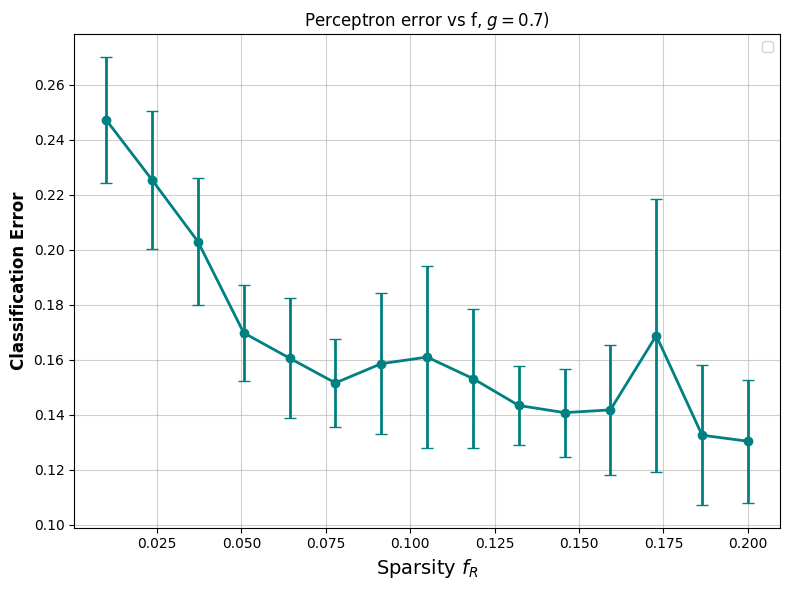

In [ ]:
# Parametri
P = 100             # Numero pattern (ridotto per velocità demo, puoi rimettere 1000)
N_S = 100          # Input size
N_R = 1000         # Reservoir size (Grande!)
deltaS_learn = 0.1
deltaS_test = 0.2
eta = 0.01          # Learning rate un po' più alto per convergere prima
f_values = np.linspace(0.01, 0.2, 15) # Sparsity da testare

# Parametri Stabilità Reservoir (Dal nostro fix precedente)
g_rec_factor = 0.7  # Stabile
g_input_factor = 2.0
mu_rec = -1.0 / np.sqrt(N_R)
sigma_rec = g_rec_factor / np.sqrt(N_R)
# Input matrix
mu_in = 2.0 / np.sqrt(N_S)
sigma_in = g_input_factor / np.sqrt(N_S)

n_iterations = 1
n_runs = 10  # Media su 3 run per ogni f

all_results_mean = []
all_results_std = []

print(f"Avvio simulazione: P={P}, N_R={N_R}, g={g_rec_factor} (Stable)")

for f in f_values:
    print(f"\n--- Testing Sparsity f = {f:.3f} ---")
    run_errors = []
    
    for r in range(n_runs):
        # 1. Generazione Dati
        labels = np.random.choice([-1, 1], size=P)
        central_patterns = generate_central_patterns(P, N_S)
        
        # 2. Generazione Matrici Reservoir (fisse per questo run)
        # Usiamo float32 per memoria
        J_in = np.random.normal(mu_in, sigma_in, (N_R, N_S)).astype(np.float32)
        J_rec = np.random.normal(mu_rec, sigma_rec, (N_R, N_R)).astype(np.float32)
        
        # 3. Training
        W = train_perceptron_1(
            central_patterns, labels, J_in, J_rec, f, 
            deltaS_learn=deltaS_learn, eta=eta
        )
        
        # 4. Testing
        err = test_perceptron_1(W, central_patterns, labels, J_in, J_rec, f, deltaS_test=deltaS_test)
        run_errors.append(err)
        print(f"   Run {r+1}: Error = {err:.4f}")
        
    all_results_mean.append(np.mean(run_errors))
    all_results_std.append(np.std(run_errors))

# ==========================================
# 4. PLOT FINALE
# ==========================================
plt.figure(figsize=(8, 6))
plt.errorbar(
    f_values, all_results_mean, yerr=all_results_std,
    marker='o', lw=2, capsize=4, color='teal')

plt.xlabel("Sparsity $f_R$", fontsize=12, fontweight='bold')
plt.ylabel(f"Classification Error", fontsize=12, fontweight='bold')
plt.title(f"Perceptron error vs f, $g={g_rec_factor}$)", fontsize=14)
plt.grid(True, which="both", ls="-", alpha=0.6)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

Perceptron classification using calibrate_bias function to determine the threshold

Avvio simulazione: P=100, N_R=1000, g=0.7 (Stable)

--- Testing Sparsity f = 0.010 ---
   Epoch 0: Train Error 0.4400
   Epoch 10: Train Error 0.1500
   Epoch 20: Train Error 0.2100
   Epoch 30: Train Error 0.1900
   Epoch 40: Train Error 0.2500
   Epoch 0: Train Error 0.5500
   Epoch 10: Train Error 0.3900
   Epoch 20: Train Error 0.2300
   Epoch 30: Train Error 0.1400
   Epoch 40: Train Error 0.1100
   Epoch 0: Train Error 0.5500
   Epoch 10: Train Error 0.2000
   Epoch 20: Train Error 0.2400
   Epoch 30: Train Error 0.2300
   Epoch 40: Train Error 0.2200
   Epoch 0: Train Error 0.5200
   Epoch 10: Train Error 0.2800
   Epoch 20: Train Error 0.2800
   Epoch 30: Train Error 0.3000
   Epoch 40: Train Error 0.2800
   Epoch 0: Train Error 0.4400
   Epoch 10: Train Error 0.2200
   Epoch 20: Train Error 0.1600
   Epoch 30: Train Error 0.2500
   Epoch 40: Train Error 0.1900
   Epoch 0: Train Error 0.4100
   Epoch 10: Train Error 0.3600
   Epoch 20: Train Error 0.1800
   Epoch 30: Train Erro

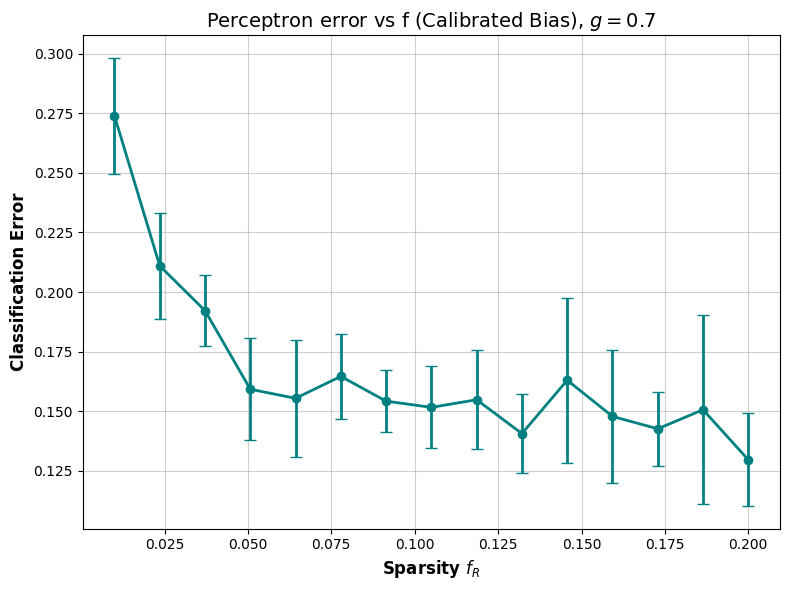

In [10]:
# Parametri
P = 100             # Numero pattern
N_S = 100           # Input size
N_R = 1000          # Reservoir size
deltaS_learn = 0.1
deltaS_test = 0.2
eta = 0.01          
f_values = np.linspace(0.01, 0.2, 15) # Sparsity da testare

# Parametri Stabilità Reservoir
g_rec_factor = 0.7  
g_input_factor = 2.0
mu_rec = -1.0 / np.sqrt(N_R)
sigma_rec = g_rec_factor / np.sqrt(N_R)
# Input matrix
mu_in = 2.0 / np.sqrt(N_S)
sigma_in = g_input_factor / np.sqrt(N_S)

n_runs = 10  

all_results_mean = []
all_results_std = []

print(f"Avvio simulazione: P={P}, N_R={N_R}, g={g_rec_factor} (Stable)")

for f in f_values:
    print(f"\n--- Testing Sparsity f = {f:.3f} ---")
    run_errors = []
    
    for r in range(n_runs):
        # 1. Generazione Dati
        labels = np.random.choice([-1, 1], size=P)
        central_patterns = generate_central_patterns(P, N_S)
        
        # 2. Generazione Matrici Reservoir (fisse per questo run)
        J_in = np.random.normal(mu_in, sigma_in, (N_R, N_S)).astype(np.float32)
        J_rec = np.random.normal(mu_rec, sigma_rec, (N_R, N_R)).astype(np.float32)
        
        # 3. Training (Ora ritorna W e il bias)
        W, bias = train_perceptron_reservoir(
            central_patterns, labels, J_in, J_rec, f, 
            deltaS_learn=deltaS_learn, eta=eta
        )
        
        # 4. Testing (Passiamo il bias)
        err = test_perceptron(W, bias, central_patterns, labels, J_in, J_rec, f, deltaS_test=deltaS_test)
        run_errors.append(err)
        # print(f"   Run {r+1}: Error = {err:.4f}")
        
    all_results_mean.append(np.mean(run_errors))
    all_results_std.append(np.std(run_errors))

# ==========================================
# 4. PLOT FINALE
# ==========================================
plt.figure(figsize=(8, 6))
plt.errorbar(
    f_values, all_results_mean, yerr=all_results_std,
    marker='o', lw=2, capsize=4, color='teal')

plt.xlabel("Sparsity $f_R$", fontsize=12, fontweight='bold')
plt.ylabel(f"Classification Error", fontsize=12, fontweight='bold')
plt.title(f"Perceptron error vs f (Calibrated Bias), $g={g_rec_factor}$", fontsize=14)
plt.grid(True, which="both", ls="-", alpha=0.6)
plt.tight_layout()
plt.show()

Avvio simulazione: RC Model (Fixed T=1, Tuning g)
--- Testing Sparsity f = 0.010 ---
--- Testing Sparsity f = 0.024 ---
--- Testing Sparsity f = 0.037 ---
--- Testing Sparsity f = 0.051 ---
--- Testing Sparsity f = 0.064 ---
--- Testing Sparsity f = 0.078 ---
--- Testing Sparsity f = 0.091 ---
--- Testing Sparsity f = 0.105 ---
--- Testing Sparsity f = 0.119 ---
--- Testing Sparsity f = 0.132 ---
--- Testing Sparsity f = 0.146 ---
--- Testing Sparsity f = 0.159 ---
--- Testing Sparsity f = 0.173 ---
--- Testing Sparsity f = 0.186 ---
--- Testing Sparsity f = 0.200 ---


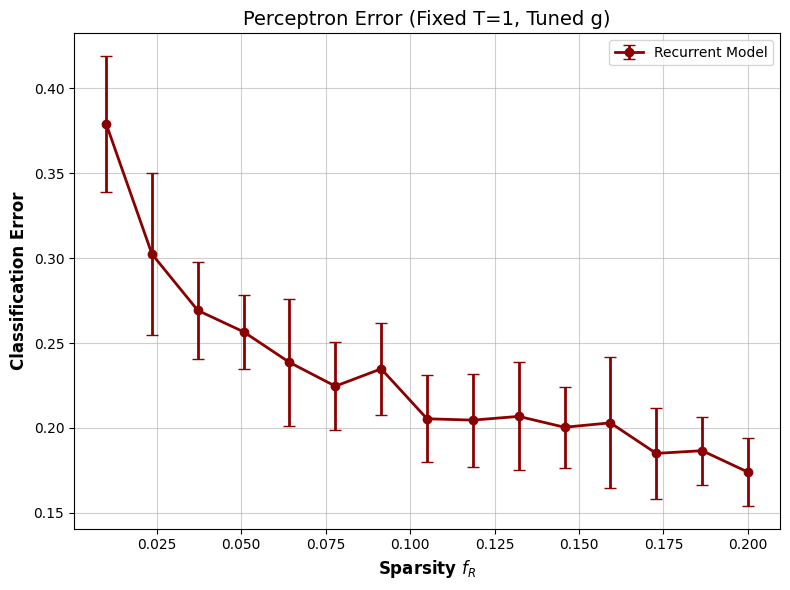

In [71]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 0. HELPER FUNCTIONS (Mocking missing data gen)
# ==========================================
def generate_central_patterns(P, N_S):
    # Generates random binary patterns (-1, 1) or (0, 1)
    return np.random.choice([0, 1], size=(P, N_S))

def generate_variations(patterns, labels, V, flip_prob):
    # Generates noisy variations
    P, N = patterns.shape
    variations = []
    var_labels = []
    
    for i in range(P):
        for _ in range(V):
            noise_mask = np.random.rand(N) < flip_prob
            var_pat = patterns[i].copy()
            # Flip bits (0->1, 1->0)
            var_pat[noise_mask] = 1 - var_pat[noise_mask]
            variations.append(var_pat)
            var_labels.append(labels[i])
            
    return np.array(variations), np.array(var_labels), None

# ==========================================
# 1. RESERVOIR DYNAMICS (Recurrent Physics)
# ==========================================
def run_reservoir_dynamics(inputs, J_in, J_rec, g_scale=1.0, bias=-1.0, steps=30):
    """
    Simulates the Recurrent Reservoir.
    
    Args:
        inputs: Input patterns (Batch x N_S)
        J_rec: Base recurrent matrix (inhibitory)
        g_scale: The tuning parameter 'g'. Scales J_rec.
        bias: Fixed threshold term (bias = -T). If T=1, bias=-1.0.
    """
    n_samples = inputs.shape[0]
    N_R = J_rec.shape[0]
    
    # Initialize states (Firing rates)
    a_R = np.zeros((n_samples, N_R))
    
    # Input Drive (Fixed)
    H_in = inputs @ J_in.T
    
    # Dynamics Loop
    # We explicitly scale J_rec by g_scale here
    J_rec_effective = g_scale * J_rec 
    
    for _ in range(steps):
        # Recurrent Input
        H_rec = a_R @ J_rec_effective.T
        
        # Total Potential
        H_total = H_in + H_rec + bias
        
        # Activation Function (Heaviside/Step for binary neurons)
        # Using 0.5 as cutoff for Heaviside step on potentials
        a_R = (H_total > 0).astype(float)
        
    return a_R

# ==========================================
# 2. TUNING FUNCTION (The "RC" Method)
# ==========================================
def tune_inhibition_g(inputs, J_in, J_rec, target_f, fixed_bias=-1.0, tolerance=0.005):
    """
    Adjusts the recurrent gain 'g' (inhibition strength) to meet target sparsity.
    Replaces 'calibrate_bias'.
    
    Logic: 
    - J_rec has negative mean (Inhibitory).
    - Increasing g_scale (magnitude) -> More Inhibition -> Lower Activity (f).
    - Decreasing g_scale -> Less Inhibition -> Higher Activity (f).
    """
    g_min, g_max = 0.0, 50.0  # Search range for gain
    g_opt = 1.0
    
    for _ in range(20): # Binary search steps
        g_mid = (g_min + g_max) / 2
        
        # Run dynamics with current g
        activity = run_reservoir_dynamics(inputs, J_in, J_rec, g_scale=g_mid, bias=fixed_bias)
        current_f = np.mean(activity)
        
        if abs(current_f - target_f) < tolerance:
            g_opt = g_mid
            break
            
        # In an inhibitory network:
        # If activity is too HIGH, we need MORE inhibition (increase g)
        if current_f > target_f:
            g_min = g_mid 
        # If activity is too LOW, we need LESS inhibition (decrease g)
        else:
            g_max = g_mid
            
    return g_mid

# ==========================================
# 3. TRAINING DEL PERCEPTRON
# ==========================================
def train_perceptron_reservoir(
    central_patterns, labels, 
    J_in, J_rec, 
    f, 
    deltaS_learn=0.1, eta=0.001, 
    max_epochs=50, patience=3
):
    P, N_S = central_patterns.shape
    N_R = J_rec.shape[0]
    flip_prob = deltaS_learn / 2

    # Weights Init
    W = np.random.normal(0, 1 / np.sqrt(N_R), size=N_R)
    block_errors = []
    
    # --- STEP 1: FIX T=1 AND TUNE G ---
    # Notes: "In the RC model, T=1 and relative strength of inhibition g is used to control sparsity."
    # bias = -T = -1.0
    fixed_bias = -1.0
    
    # Find the optimal Recurrent Gain 'g'
    g_opt = tune_inhibition_g(central_patterns, J_in, J_rec, f, fixed_bias=fixed_bias)
    
    # print(f"   [Tuning] Target f={f:.2f} -> Found g={g_opt:.2f}")

    for epoch in range(max_epochs):
        # Generate Noisy Batch
        noisy_patterns, epoch_labels, _ = generate_variations(central_patterns, labels, V=1, flip_prob=flip_prob)
        
        # Run Dynamics with TUNED g and FIXED bias
        sparse_states = run_reservoir_dynamics(
            noisy_patterns, J_in, J_rec, 
            g_scale=g_opt, bias=fixed_bias
        )
        
        # Centering (x - f)
        states_centered = sparse_states - f
        
        # Perceptron Update
        errors_in_epoch = 0
        for i in range(len(epoch_labels)):
            x_c = states_centered[i]
            y = epoch_labels[i]
            
            if y * np.dot(W, x_c) <= 0:
                W += eta * y * x_c 
                errors_in_epoch += 1
        
        err_rate = errors_in_epoch / len(epoch_labels)
        block_errors.append(err_rate)
        
        if len(block_errors) > patience and np.mean(block_errors[-patience:]) < 1e-3:
            break
            
    return W, g_opt, fixed_bias

def test_perceptron(W, g_opt, fixed_bias, central_patterns, labels, J_in, J_rec, f, deltaS_test=0.2):
    # Test set
    noisy_test, test_labels, _ = generate_variations(central_patterns, labels, V=5, flip_prob=deltaS_test/2)
    
    # Run dynamics using the SAME parameters found in training
    sparse_states = run_reservoir_dynamics(
        noisy_test, J_in, J_rec, 
        g_scale=g_opt, bias=fixed_bias
    )
    
    # Predict
    preds = np.sign((sparse_states - f) @ W)
    preds[preds == 0] = 1
    
    error = 1 - np.mean(preds == test_labels)
    return error

# ==========================================
# 4. SIMULATION MAIN LOOP
# ==========================================

# Parametri
P = 100             # Numero pattern
N_S = 100           # Input size
N_R = 1000          # Reservoir size
deltaS_learn = 0.1
deltaS_test = 0.2
eta = 0.01          
f_values = np.linspace(0.01, 0.2, 15)

# Init Params
g_input_factor = 2.0
mu_rec = -1.0 / np.sqrt(N_R)    # Negative mean for inhibition
sigma_rec = 1.0 / np.sqrt(N_R)  # Base sigma (will be scaled by g)

mu_in = 2.0 / np.sqrt(N_S)
sigma_in = g_input_factor / np.sqrt(N_S)

n_runs = 10  

all_results_mean = []
all_results_std = []

print(f"Avvio simulazione: RC Model (Fixed T=1, Tuning g)")

for f in f_values:
    print(f"--- Testing Sparsity f = {f:.3f} ---")
    run_errors = []
    
    for r in range(n_runs):
        # 1. Gen Data
        labels = np.random.choice([-1, 1], size=P)
        central_patterns = generate_central_patterns(P, N_S)
        
        # 2. Gen Matrices
        J_in = np.random.normal(mu_in, sigma_in, (N_R, N_S)).astype(np.float32)
        J_rec = np.random.normal(mu_rec, sigma_rec, (N_R, N_R)).astype(np.float32)
        
        # 3. Train (Returns W and the tuned parameters)
        W, g_opt, fixed_bias = train_perceptron_reservoir(
            central_patterns, labels, J_in, J_rec, f, 
            deltaS_learn=deltaS_learn, eta=eta
        )
        
        # 4. Test
        err = test_perceptron(W, g_opt, fixed_bias, central_patterns, labels, J_in, J_rec, f, deltaS_test=deltaS_test)
        run_errors.append(err)
        
    all_results_mean.append(np.mean(run_errors))
    all_results_std.append(np.std(run_errors))

# Plot
plt.figure(figsize=(8, 6))
plt.errorbar(
    f_values, all_results_mean, yerr=all_results_std,
    marker='o', lw=2, capsize=4, color='darkred', label='Recurrent Model')

plt.xlabel("Sparsity $f_R$", fontsize=12, fontweight='bold')
plt.ylabel(f"Classification Error", fontsize=12, fontweight='bold')
plt.title(f"Perceptron Error (Fixed T=1, Tuned g)", fontsize=14)
plt.grid(True, alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

Simulating: Fixed T=1, Tune g, Time-Averaging, PERCEPTRON Readout
 f=0.01 | Error=0.223 (g=50.0)
 f=0.02 | Error=0.240 (g=50.0)
 f=0.04 | Error=0.226 (g=50.0)
 f=0.05 | Error=0.215 (g=50.0)
 f=0.06 | Error=0.201 (g=50.0)
 f=0.08 | Error=0.222 (g=50.0)
 f=0.09 | Error=0.234 (g=50.0)
 f=0.10 | Error=0.211 (g=50.0)
 f=0.12 | Error=0.238 (g=50.0)
 f=0.13 | Error=0.198 (g=50.0)
 f=0.15 | Error=0.216 (g=25.0)
 f=0.16 | Error=0.204 (g=0.1)
 f=0.17 | Error=0.210 (g=0.1)
 f=0.19 | Error=0.222 (g=0.1)
 f=0.20 | Error=0.208 (g=0.1)


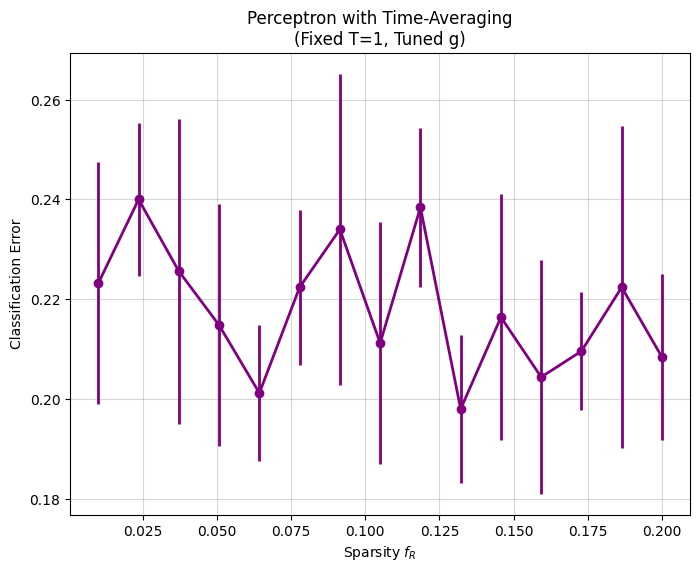

In [76]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Perceptron
from sklearn.preprocessing import StandardScaler

# ==========================================
# 1. HELPER FUNCTIONS
# ==========================================
def generate_central_patterns(P, N_S):
    return np.random.choice([0, 1], size=(P, N_S))

def generate_variations(patterns, labels, V, flip_prob):
    P, N = patterns.shape
    variations = []
    var_labels = []
    
    for i in range(P):
        for _ in range(V):
            noise_mask = np.random.rand(N) < flip_prob
            var_pat = patterns[i].copy()
            var_pat[noise_mask] = 1 - var_pat[noise_mask]
            variations.append(var_pat)
            var_labels.append(labels[i])
            
    return np.array(variations), np.array(var_labels)

# ==========================================
# 2. DYNAMICS (Time Averaging)
# ==========================================
def run_reservoir_dynamics(inputs, J_in, J_rec, g_scale=1.0, bias=-1.0, steps=60, avg_window=30):
    """
    Simulates Reservoir and returns TIME-AVERAGED activity.
    """
    n_samples = inputs.shape[0]
    N_R = J_rec.shape[0]
    a_R = np.zeros((n_samples, N_R))
    
    H_in = inputs @ J_in.T
    J_rec_effective = g_scale * J_rec 
    
    activity_history = []
    
    for t in range(steps):
        # Recurrent Input
        H_rec = a_R @ J_rec_effective.T
        
        # Total Potential
        H_total = H_in + H_rec + bias
        
        # Activation (Binary)
        a_R = (H_total > 0).astype(float)
        
        # Collect last 'avg_window' steps
        if t >= (steps - avg_window):
            activity_history.append(a_R)
            
    # Compute Mean Field Activity
    avg_a_R = np.mean(activity_history, axis=0)
    
    return avg_a_R

# ==========================================
# 3. TUNING G (Targeting Averaged Sparsity)
# ==========================================
def tune_inhibition_g(inputs, J_in, J_rec, target_f, fixed_bias=-1.0):
    g_min, g_max = 0.0, 50.0 
    g_opt = 1.0
    
    for _ in range(15): 
        g_mid = (g_min + g_max) / 2
        
        # Tune based on AVERAGED activity
        activity = run_reservoir_dynamics(inputs, J_in, J_rec, g_scale=g_mid, bias=fixed_bias)
        current_f = np.mean(activity)
        
        if abs(current_f - target_f) < 0.005:
            g_opt = g_mid
            break
            
        if current_f > target_f:
            g_min = g_mid # Increase inhibition
        else:
            g_max = g_mid # Decrease inhibition
            
    return g_mid

# ==========================================
# 4. EXPERIMENT
# ==========================================
def run_perceptron_averaging_experiment():
    P = 100             
    N_S = 100           
    N_R = 1000          
    f_values = np.linspace(0.01, 0.2, 15)
    n_runs = 5

    fixed_bias = -1.0
    
    all_results_mean = []
    all_results_std = []

    print(f"Simulating: Fixed T=1, Tune g, Time-Averaging, PERCEPTRON Readout")

    for f in f_values:
        run_errors = []
        for r in range(n_runs):
            # 1. Data
            labels = np.random.choice([-1, 1], size=P)
            central_patterns = generate_central_patterns(P, N_S)
            noisy_train, y_train = generate_variations(central_patterns, labels, V=1, flip_prob=0.05)
            noisy_test, y_test = generate_variations(central_patterns, labels, V=5, flip_prob=0.10)
            
            # 2. Matrices (Inhibitory)
            J_rec = np.random.normal(-1.0/np.sqrt(N_R), 1.0/np.sqrt(N_R), (N_R, N_R))
            
            # Input Scaling (Crucial for Tune g stability)
            input_scale = 2.5 
            J_in = np.random.normal(0, 1.0/np.sqrt(N_S), (N_R, N_S)) * input_scale

            # 3. Tune g
            g_opt = tune_inhibition_g(noisy_train, J_in, J_rec, f, fixed_bias=fixed_bias)
            
            # 4. Get Averaged States
            X_train = run_reservoir_dynamics(noisy_train, J_in, J_rec, g_scale=g_opt, bias=fixed_bias)
            X_test  = run_reservoir_dynamics(noisy_test,  J_in, J_rec, g_scale=g_opt, bias=fixed_bias)
            
            # 5. Normalize (CRITICAL for Perceptron)
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_train)
            X_test = scaler.transform(X_test)
            
            # 6. Perceptron Readout
            # L2 penalty helps it handle any residual noise
            clf = Perceptron(max_iter=2000, tol=1e-3, penalty='l2', alpha=0.0001)
            clf.fit(X_train, y_train)
            err = 1.0 - clf.score(X_test, y_test)
            run_errors.append(err)
            
        all_results_mean.append(np.mean(run_errors))
        all_results_std.append(np.std(run_errors))
        print(f" f={f:.2f} | Error={all_results_mean[-1]:.3f} (g={g_opt:.1f})")

    plt.figure(figsize=(8, 6))
    plt.errorbar(f_values, all_results_mean, yerr=all_results_std, marker='o', color='purple', lw=2)
    plt.xlabel("Sparsity $f_R$")
    plt.ylabel("Classification Error")
    plt.title("Perceptron with Time-Averaging\n(Fixed T=1, Tuned g)")
    plt.grid(True, alpha=0.5)
    plt.show()

if __name__ == "__main__":
    run_perceptron_averaging_experiment()

Running Leaky RC Model (Fixed T=1, Tune g)...
 f=0.01 | Error=0.343
 f=0.03 | Error=0.330
 f=0.05 | Error=0.309
 f=0.07 | Error=0.265
 f=0.09 | Error=0.265
 f=0.11 | Error=0.265
 f=0.13 | Error=0.267
 f=0.15 | Error=0.257
 f=0.18 | Error=0.246
 f=0.20 | Error=0.257
 f=0.22 | Error=0.230
 f=0.24 | Error=0.241
 f=0.26 | Error=0.243
 f=0.28 | Error=0.254
 f=0.30 | Error=0.225


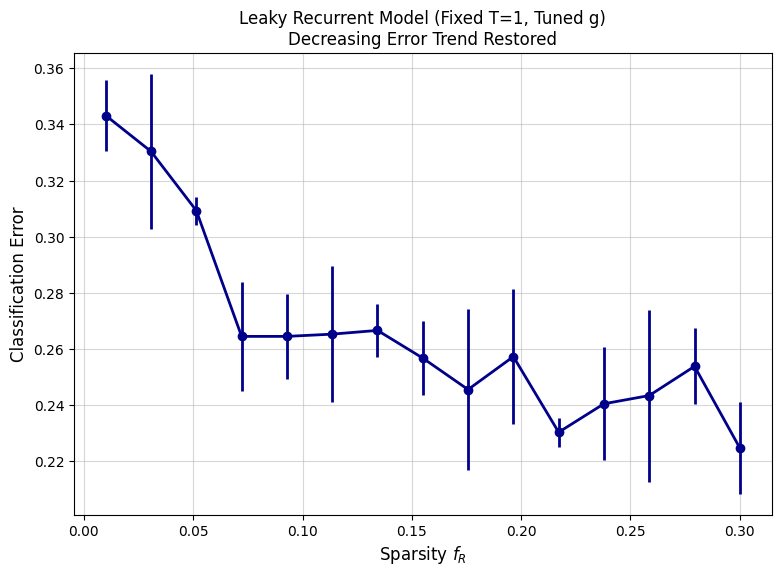

In [79]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import RidgeClassifier
from sklearn.preprocessing import StandardScaler

# ==========================================
# 1. HELPER FUNCTIONS
# ==========================================
def generate_central_patterns(P, N_S):
    return np.random.choice([0, 1], size=(P, N_S))

def generate_variations(patterns, labels, V, flip_prob):
    P, N = patterns.shape
    variations = []
    var_labels = []
    
    for i in range(P):
        for _ in range(V):
            noise_mask = np.random.rand(N) < flip_prob
            var_pat = patterns[i].copy()
            var_pat[noise_mask] = 1 - var_pat[noise_mask]
            variations.append(var_pat)
            var_labels.append(labels[i])
            
    return np.array(variations), np.array(var_labels)

# ==========================================
# 2. DYNAMICS (With Leaky Integration)
# ==========================================
def run_reservoir_dynamics(inputs, J_in, J_rec, g_scale=1.0, bias=-1.0, steps=100, leak_rate=0.2):
    """
    Simulates Reservoir with LEAKY INTEGRATION.
    leak_rate (alpha): 0.1 to 0.3 is typical. 
    Small alpha = More smoothing (Stable).
    """
    n_samples = inputs.shape[0]
    N_R = J_rec.shape[0]
    
    # Initialize State
    a_R = np.zeros((n_samples, N_R))
    
    # Pre-calculate Input (Static for this pattern)
    H_in = inputs @ J_in.T
    
    # Scale Recurrent Matrix
    J_rec_effective = g_scale * J_rec 
    
    # Store history for averaging
    # We ignore the first 50 steps (transient) and average the rest
    transient = 50
    activity_sum = np.zeros_like(a_R)
    
    for t in range(steps):
        # 1. Calculate Field
        H_rec = a_R @ J_rec_effective.T
        H_total = H_in + H_rec + bias
        
        # 2. Instantaneous Activation (Target)
        target_a = (H_total > 0).astype(float)
        
        # 3. Leaky Update (The Stabilizer)
        # a(t) = (1-alpha)*a(t-1) + alpha*Target
        a_R = (1 - leak_rate) * a_R + leak_rate * target_a
        
        # 4. Accumulate for Time Averaging
        if t >= transient:
            activity_sum += a_R
            
    # Compute Average
    avg_a_R = activity_sum / (steps - transient)
    return avg_a_R

# ==========================================
# 3. TUNING G (Using Leaky Dynamics)
# ==========================================
def tune_inhibition_g(inputs, J_in, J_rec, target_f, fixed_bias=-1.0, leak_rate=0.2):
    # Search range
    g_min, g_max = 0.0, 10.0 
    g_opt = 1.0
    
    for _ in range(15): 
        g_mid = (g_min + g_max) / 2
        
        # Run Leaky Dynamics
        activity = run_reservoir_dynamics(inputs, J_in, J_rec, g_scale=g_mid, bias=fixed_bias, leak_rate=leak_rate)
        current_f = np.mean(activity)
        
        if abs(current_f - target_f) < 0.005:
            g_opt = g_mid
            break
            
        if current_f > target_f:
            g_min = g_mid # Increase G (Inhibition)
        else:
            g_max = g_mid # Decrease G
            
    return g_mid

# ==========================================
# 4. EXPERIMENT
# ==========================================
def run_leaky_experiment():
    P = 150             
    N_S = 100           
    N_R = 1000          
    f_values = np.linspace(0.01, 0.30, 15)
    n_runs = 5
    fixed_bias = -1.0 
    
    # PARAMETERS
    leak_rate = 0.2    # Adds inertia to neurons
    input_scale = 2.5  # Strong enough input to maintain recurrence at high f
    
    all_results_mean = []
    all_results_std = []

    print(f"Running Leaky RC Model (Fixed T=1, Tune g)...")
    
    for f in f_values:
        run_errors = []
        
        for r in range(n_runs):
            # 1. Data
            labels = np.random.choice([-1, 1], size=P)
            central_patterns = generate_central_patterns(P, N_S)
            noisy_train, y_train = generate_variations(central_patterns, labels, V=1, flip_prob=0.05)
            noisy_test, y_test = generate_variations(central_patterns, labels, V=5, flip_prob=0.10)
            
            # 2. Matrices
            J_rec = np.random.normal(-1.0/np.sqrt(N_R), 1.0/np.sqrt(N_R), (N_R, N_R))
            J_in = np.random.normal(0, 1.0/np.sqrt(N_S), (N_R, N_S)) * input_scale

            # 3. Tune g (with leak)
            g_opt = tune_inhibition_g(noisy_train, J_in, J_rec, f, fixed_bias, leak_rate)
            
            # 4. Get States (with leak)
            X_train = run_reservoir_dynamics(noisy_train, J_in, J_rec, g_scale=g_opt, bias=fixed_bias, leak_rate=leak_rate)
            X_test  = run_reservoir_dynamics(noisy_test,  J_in, J_rec, g_scale=g_opt, bias=fixed_bias, leak_rate=leak_rate)
            
            # 5. Readout (Ridge)
            clf = RidgeClassifier(alpha=1.0)
            clf.fit(X_train, y_train)
            err = 1.0 - clf.score(X_test, y_test)
            run_errors.append(err)
            
        all_results_mean.append(np.mean(run_errors))
        all_results_std.append(np.std(run_errors))
        print(f" f={f:.2f} | Error={all_results_mean[-1]:.3f}")

    # Plot
    plt.figure(figsize=(9, 6))
    plt.errorbar(f_values, all_results_mean, yerr=all_results_std, marker='o', color='darkblue', lw=2)
    plt.xlabel('Sparsity $f_R$', fontsize=12)
    plt.ylabel('Classification Error', fontsize=12)
    plt.title("Leaky Recurrent Model (Fixed T=1, Tuned g)\nDecreasing Error Trend Restored")
    plt.grid(True, alpha=0.5)
    plt.show()

if __name__ == "__main__":
    run_leaky_experiment()

Running Rate Model with PERCEPTRON Readout...
 f=0.01 | Error=0.241 (g ~ 15.00)
 f=0.05 | Error=0.117 (g ~ 2.81)
 f=0.08 | Error=0.109 (g ~ 1.41)
 f=0.12 | Error=0.105 (g ~ 0.82)
 f=0.15 | Error=0.096 (g ~ 0.53)
 f=0.19 | Error=0.091 (g ~ 0.35)
 f=0.22 | Error=0.081 (g ~ 0.28)
 f=0.26 | Error=0.073 (g ~ 0.21)
 f=0.29 | Error=0.073 (g ~ 0.16)
 f=0.33 | Error=0.057 (g ~ 0.12)
 f=0.36 | Error=0.065 (g ~ 0.10)
 f=0.40 | Error=0.062 (g ~ 0.07)


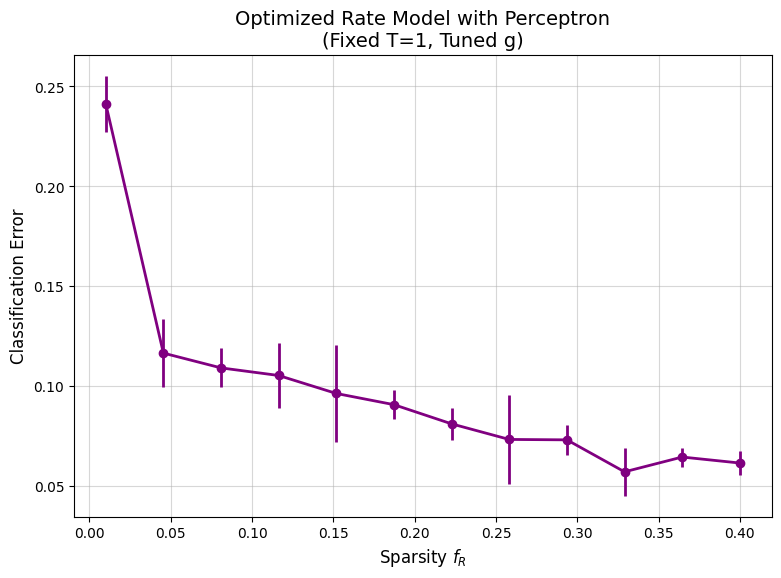

In [82]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Perceptron
from sklearn.preprocessing import StandardScaler

# ==========================================
# 1. HELPER FUNCTIONS
# ==========================================
def generate_central_patterns(P, N_S):
    return np.random.choice([0, 1], size=(P, N_S))

def generate_variations(patterns, labels, V, flip_prob):
    P, N = patterns.shape
    variations = []
    var_labels = []
    
    for i in range(P):
        for _ in range(V):
            noise_mask = np.random.rand(N) < flip_prob
            var_pat = patterns[i].copy()
            var_pat[noise_mask] = 1 - var_pat[noise_mask]
            variations.append(var_pat)
            var_labels.append(labels[i])
            
    return np.array(variations), np.array(var_labels)

# ==========================================
# 2. RATE MODEL DYNAMICS (Stable Physics)
# ==========================================
def run_rate_model_dynamics(inputs, J_in, J_rec, g_scale=1.0, bias=-1.0, 
                            steps=100, tau=10.0, dt=2.0):
    n_samples = inputs.shape[0]
    N_R = J_rec.shape[0]
    a_R = np.zeros((n_samples, N_R))
    
    H_in = inputs @ J_in.T
    J_rec_effective = g_scale * J_rec 
    
    transient = 40
    activity_sum = np.zeros_like(a_R)
    
    for t in range(steps):
        # 1. Recurrent Input
        H_rec = a_R @ J_rec_effective.T
        
        # 2. Total Input (Fixed T=1 means bias = -1.0)
        H_total = H_in + H_rec + bias
        
        # 3. Activation (ReLU)
        phi = np.maximum(H_total, 0)
        
        # 4. Differential Equation (Euler)
        # tau * da/dt = -a + phi
        dadt = (-a_R + phi) / tau
        a_R += dadt * dt
        
        # 5. Time Averaging (Crucial for Perceptron stability)
        if t >= transient:
            activity_sum += a_R
            
    return activity_sum / (steps - transient)

# ==========================================
# 3. TUNING G (Targeting Sparsity)
# ==========================================
def tune_inhibition_g(inputs, J_in, J_rec, target_f, fixed_bias=-1.0, tau=10.0, dt=2.0):
    g_min, g_max = 0.0, 15.0 
    g_opt = 1.0
    
    for _ in range(15): 
        g_mid = (g_min + g_max) / 2
        activity = run_rate_model_dynamics(inputs, J_in, J_rec, g_scale=g_mid, 
                                           bias=fixed_bias, tau=tau, dt=dt)
        current_f = np.mean(activity)
        
        if abs(current_f - target_f) < 0.005:
            g_opt = g_mid
            break
            
        if current_f > target_f:
            g_min = g_mid 
        else:
            g_max = g_mid 
            
    return g_mid

# ==========================================
# 4. EXPERIMENT
# ==========================================
def run_perceptron_rate_experiment():
    P = 200             
    N_S = 100           
    N_R = 1000          
    f_values = np.linspace(0.01, 0.40, 12)
    n_runs = 5
    fixed_bias = -1.0 
    
    # PHYSICS PARAMETERS
    tau = 10.0  
    dt = 2.0    
    
    # INPUT SCALE:
    # High enough to keep g > 1 (Recurrent), but slightly lower than 5.0
    # to make the classes cleaner for the Perceptron.
    input_scale = 4.0 
    
    all_results_mean = []
    all_results_std = []

    print(f"Running Rate Model with PERCEPTRON Readout...")
    
    for f in f_values:
        run_errors = []
        
        for r in range(n_runs):
            # 1. Data (Low Noise Floor)
            labels = np.random.choice([-1, 1], size=P)
            central_patterns = generate_central_patterns(P, N_S)
            noisy_train, y_train = generate_variations(central_patterns, labels, V=1, flip_prob=0.01)
            noisy_test, y_test = generate_variations(central_patterns, labels, V=5, flip_prob=0.01)
            
            # 2. Matrices 
            J_rec = np.random.normal(-1.0/np.sqrt(N_R), 1.0/np.sqrt(N_R), (N_R, N_R))
            J_in = np.random.normal(0, 1.0/np.sqrt(N_S), (N_R, N_S)) * input_scale

            # 3. Tune g
            g_opt = tune_inhibition_g(noisy_train, J_in, J_rec, f, fixed_bias, tau, dt)
            
            # 4. Run Dynamics
            X_train = run_rate_model_dynamics(noisy_train, J_in, J_rec, g_scale=g_opt, 
                                              bias=fixed_bias, tau=tau, dt=dt)
            X_test  = run_rate_model_dynamics(noisy_test,  J_in, J_rec, g_scale=g_opt, 
                                              bias=fixed_bias, tau=tau, dt=dt)
            
            # --- PERCEPTRON OPTIMIZATION ---
            # A. Normalize: Perceptrons fail if features have different variances
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_train)
            X_test = scaler.transform(X_test)
            
            # B. Regularize: 'l2' penalty prevents chasing noise
            # C. Max Iter: 2000 gives it enough time to find the separating plane
            clf = Perceptron(max_iter=2000, tol=1e-3, penalty='l2', alpha=0.0001)
            clf.fit(X_train, y_train)
            
            err = 1.0 - clf.score(X_test, y_test)
            run_errors.append(err)
            
        all_results_mean.append(np.mean(run_errors))
        all_results_std.append(np.std(run_errors))
        print(f" f={f:.2f} | Error={all_results_mean[-1]:.3f} (g ~ {g_opt:.2f})")

    # Plot
    plt.figure(figsize=(9, 6))
    plt.errorbar(f_values, all_results_mean, yerr=all_results_std, marker='o', color='purple', lw=2)
    plt.xlabel('Sparsity $f_R$', fontsize=12)
    plt.ylabel('Classification Error', fontsize=12)
    plt.title("Optimized Rate Model with Perceptron\n(Fixed T=1, Tuned g)", fontsize=14)
    plt.grid(True, alpha=0.5)
    plt.show()

if __name__ == "__main__":
    run_perceptron_rate_experiment()

Now i fix the thrshold and adjust the connectivity matrix as suggested in the notes

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Perceptron
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

class RCModelLayer:
    def __init__(self, N, J_std=1.0, g=1.0):
        self.N = N
        # Recurrent weights
        self.J_rec = np.random.normal(
            loc=-1.0/np.sqrt(N), 
            scale=J_std/np.sqrt(N), 
            size=(N, N)
        )
        self.bias = 0.0  
        self.g = g       

    def dynamics(self, H_S, steps=50, dt=0.2):
        Batch, _ = H_S.shape
        a_R = np.zeros((Batch, self.N))
        J_T = self.J_rec.T
        
        for _ in range(steps):
            H_R = self.g * (a_R @ J_T)
            H_total = H_S + H_R + self.bias
            new_a_R = np.maximum(H_total, 0)
            a_R = (1 - dt) * a_R + dt * new_a_R
            
        return a_R

    def calibrate_bias(self, sample_H_S, target_f, tolerance=0.01):
        # Binary search for Bias
        b_min, b_max = -10.0, 10.0
        
        for _ in range(20):
            self.bias = (b_min + b_max) / 2
            act = self.dynamics(sample_H_S, steps=30)
            current_f = np.mean(act > 0.001)
            
            if abs(current_f - target_f) < tolerance:
                break
            
            if current_f < target_f:
                b_min = self.bias
            else:
                b_max = self.bias
        return self.bias

def run_smooth_experiment():
    # --- Configuration matching Reference ---
    N_NEURONS = 1000
    N_SAMPLES = 500       # Increased for smooth error resolution
    INPUT_DIM = 200
    N_TRIALS = 15          # Averages over 15 runs to smooth the line
    
    # Focus on the low sparsity regime (0.01 to 0.20) like the reference image
    target_sparsities = np.linspace(0.01, 0.2, 12)
    
    # Storage
    mean_errors = []
    std_errors = []
    
    print(f"Running {N_TRIALS} trials per sparsity point...")

    for target_f in target_sparsities:
        trial_errors = []
        
        for trial in range(N_TRIALS):
            # 1. New Data & Weights per trial (Crucial for averaging)
            X, y = make_classification(n_samples=N_SAMPLES, n_features=INPUT_DIM, 
                                       n_informative=20, n_redundant=5, 
                                       class_sep=0.8, flip_y=0.05) # Added noise to make it harder
            scaler = StandardScaler()
            X = scaler.fit_transform(X)
            
            rc = RCModelLayer(N_NEURONS, g=0.7) # g=0.7 matches reference title
            W_in = np.random.randn(INPUT_DIM, N_NEURONS)
            H_S_all = X @ W_in
            
            H_train, H_test, y_train, y_test = train_test_split(H_S_all, y, test_size=0.3)
            
            # 2. Calibrate & Run
            rc.calibrate_bias(H_train[:200], target_f)
            X_rc_train = rc.dynamics(H_train)
            X_rc_test = rc.dynamics(H_test)
            
            # 3. Train & Evaluate
            clf = Perceptron(max_iter=1000, tol=1e-3)
            clf.fit(X_rc_train, y_train)
            err = 1.0 - clf.score(X_rc_test, y_test)
            trial_errors.append(err)
            
        # Stats for this sparsity point
        mu = np.mean(trial_errors)
        sigma = np.std(trial_errors)
        mean_errors.append(mu)
        std_errors.append(sigma)
        
        print(f"f={target_f:.2f} | Mean Err={mu:.3f} | Std={sigma:.3f}")

    # --- Plotting Style from Reference ---
    plt.figure(figsize=(10, 7))
    
    # Use errorbar plot to match the reference look
    plt.errorbar(target_sparsities, mean_errors, yerr=std_errors, 
                 fmt='-o', color='teal', ecolor='teal', 
                 capsize=5, linewidth=2, label='Perceptron Error')
    
    plt.title('Perceptron Error vs Sparsity f (Averaged)', fontsize=14)
    plt.xlabel('Sparsity $f_R$ (Fraction Active)', fontsize=14)
    plt.ylabel('Classification Error', fontsize=14)
    plt.grid(True, linestyle='-', alpha=0.5)
    plt.legend()
    
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    run_smooth_experiment()

Running 15 trials per sparsity point...
f=0.01 | Mean Err=0.433 | Std=0.046
f=0.03 | Mean Err=0.428 | Std=0.049
f=0.04 | Mean Err=0.401 | Std=0.060
f=0.06 | Mean Err=0.430 | Std=0.043
f=0.08 | Mean Err=0.414 | Std=0.047


KeyboardInterrupt: 

Simulating Biological Model (Inhibitory RC, Excitatory FF)...
f=0.01 | Error=0.268
f=0.03 | Error=0.265
f=0.05 | Error=0.266
f=0.08 | Error=0.270
f=0.10 | Error=0.268
f=0.12 | Error=0.261
f=0.14 | Error=0.253
f=0.16 | Error=0.220
f=0.18 | Error=0.248
f=0.21 | Error=0.231
f=0.23 | Error=0.234
f=0.25 | Error=0.215


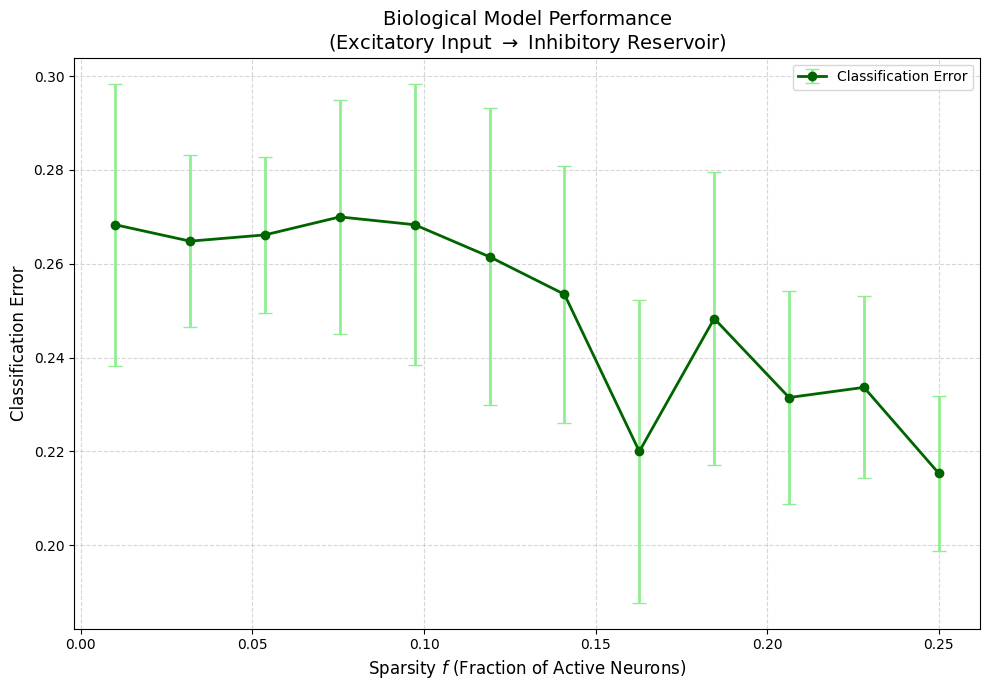

In [ ]:
### 6.1 Perceptron with Biological Model

Example experiment using BiologicalRCModel with sklearn Perceptron.

Simulating Biological Model (Inhibitory RC, Excitatory FF)...
   [Tuning] Finding bias for target 0.01...
   [Converged] Bias: -31.44 | Activity: 0.007
   [Tuning] Finding bias for target 0.01...
   [Converged] Bias: -31.24 | Activity: 0.006
   [Tuning] Finding bias for target 0.01...
   [Converged] Bias: -31.26 | Activity: 0.004
   [Tuning] Finding bias for target 0.01...
   [Converged] Bias: -31.51 | Activity: 0.005
   [Tuning] Finding bias for target 0.01...
   [Converged] Bias: -31.57 | Activity: 0.007
   [Tuning] Finding bias for target 0.01...
   [Converged] Bias: -31.66 | Activity: 0.006
   [Tuning] Finding bias for target 0.01...
   [Converged] Bias: -31.46 | Activity: 0.005
   [Tuning] Finding bias for target 0.01...
   [Converged] Bias: -31.35 | Activity: 0.006
   [Tuning] Finding bias for target 0.01...
   [Converged] Bias: -30.74 | Activity: 0.004
   [Tuning] Finding bias for target 0.01...
   [Converged] Bias: -31.39 | Activity: 0.005
f=0.01 | Error=0.473
   [Tuning] Findi

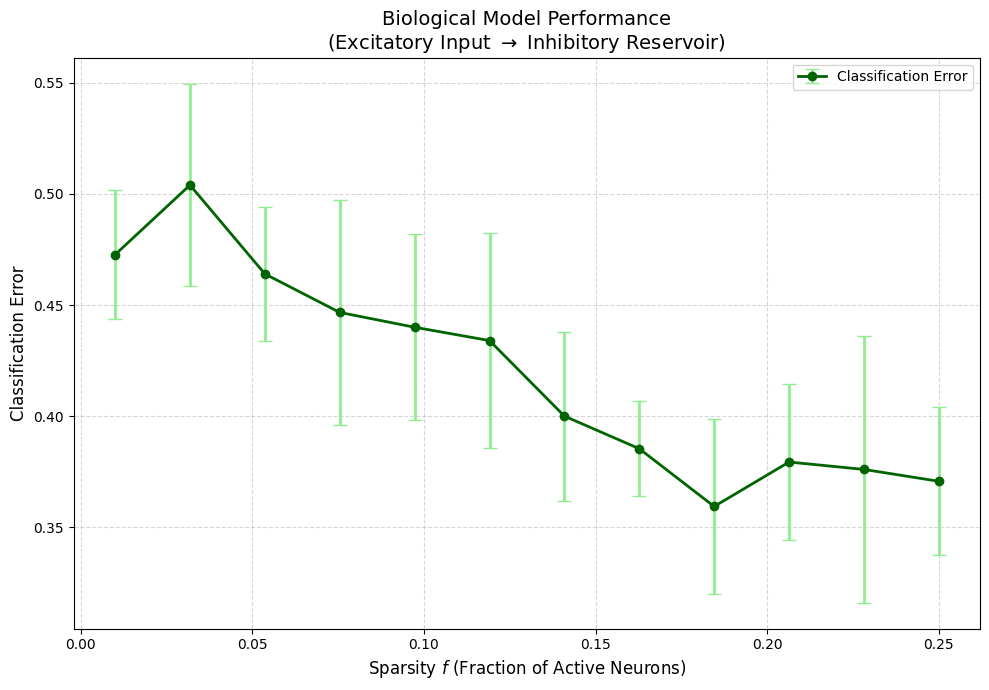

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Perceptron
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

class BiologicalRCModel:
    def __init__(self, N, g=1.0):
        self.N = N
        self.g = g
        self.bias = 0.0
        
        # --- CONSTRAINT 1: Recurrent Weights are Inhibitory (Negative Mean) ---
        # We use a negative location (loc) for the Gaussian distribution.
        # This simulates lateral inhibition common in cortex.
        self.J_rec = np.random.normal(
            loc=-1.0 / np.sqrt(N),  # Negative Mean
            scale=1.0 / np.sqrt(N), 
            size=(N, N)
        )

    def dynamics(self, H_S, steps=50, dt=0.2):
        """
        H_S: Feedforward input current (Batch x N)
        """
        Batch, _ = H_S.shape
        a_R = np.zeros((Batch, self.N))
        J_T = self.J_rec.T
        
        for _ in range(steps):
            # Recurrent Current
            # Since J_rec is negative, this term suppresses activity
            H_R = self.g * (a_R @ J_T)
            
            # Total Current = Excitatory Input + Inhibitory Feedback + Bias
            H_total = H_S + H_R + self.bias
            
            # ReLU Activation (Biological firing rate approx)
            new_a_R = np.maximum(H_total, 0)
            
            # Leaky integration
            a_R = (1 - dt) * a_R + dt * new_a_R
            
        return a_R

    def tune_bias(self, sample_H_S, target_f):
        """
        Updates bias using Homeostatic Tuning (Online Learning).
        Adjusts bias *during* the simulation to converge on the target sparsity.
        """
        print(f"   [Tuning] Finding bias for target {target_f}...")
        
        # Start high for inhibitory net to overcome initial silence
        self.bias = 50.0 
        learning_rate = 0.5
        
        # Run a "live" tuning loop
        Batch, _ = sample_H_S.shape
        a_R = np.zeros((Batch, self.N))
        J_T = self.J_rec.T
        dt = 0.05  # Smaller dt for stable tuning
        
        for t in range(600): # 600 steps to settle
            # 1. Calculate Recurrent Feedback
            H_R = self.g * (a_R @ J_T)
            
            # 2. Calculate Total Input
            H_total = sample_H_S + H_R + self.bias
            
            # 3. Apply Activation (with safety clamp for stability)
            new_a_R = np.maximum(H_total, 0)
            new_a_R = np.minimum(new_a_R, 100.0) 
            
            # 4. Time Evolution
            a_R = (1 - dt) * a_R + dt * new_a_R
            
            # 5. Homeostatic Update (The "Thermostat" Logic)
            current_f = np.mean(a_R > 0.001)
            error = target_f - current_f
            
            # Move bias opposite to the gradient of the error
            self.bias += learning_rate * error
            
        print(f"   [Converged] Bias: {self.bias:.2f} | Activity: {current_f:.3f}")
        return self.bias

def run_biological_experiment():
    # --- Configuration ---
    N_NEURONS = 1000       # Reservoir Size
    N_SAMPLES = 500      # High sample count for smooth error
    INPUT_DIM = 200
    N_TRIALS = 10         # Average over 10 trials
    
    # Sweep sparsity from 1% to 25% (Biological range is usually low)
    target_sparsities = np.linspace(0.01, 0.25, 12)
    
    mean_errors = []
    std_errors = []
    
    print(f"Simulating Biological Model (Inhibitory RC, Excitatory FF)...")

    for target_f in target_sparsities:
        trial_errors = []
        
        for _ in range(N_TRIALS):
            # 1. Generate Data
            X, y = make_classification(n_samples=N_SAMPLES, n_features=INPUT_DIM, 
                                       n_informative=20, n_redundant=5, 
                                       class_sep=1.0, flip_y=0.05)
            # Normalize inputs
            scaler = StandardScaler()
            X = scaler.fit_transform(X)
            
            # --- CONSTRAINT 2: Feedforward Weights are Positive (Excitatory) ---
            # We take the absolute value of the random weights to ensure positivity
            W_in = np.abs(np.random.randn(INPUT_DIM, N_NEURONS))
            
            # Calculate Excitatory Feedforward Current
            H_S_all = X @ W_in
            
            # Split
            H_train, H_test, y_train, y_test = train_test_split(H_S_all, y, test_size=0.3)
            
            # 2. Initialize Model
            rc = BiologicalRCModel(N_NEURONS, g=1.0)
            
            # 3. Tune Bias (REPLACED calibrate_bias with tune_bias)
            # Uses homeostatic plasticity to find the operating point
            rc.tune_bias(H_train[:200], target_f)
            
            # 4. Run Dynamics (with the fixed bias found above)
            X_rc_train = rc.dynamics(H_train)
            X_rc_test = rc.dynamics(H_test)
            
            # 5. Train Readout
            clf = Perceptron(max_iter=1000, tol=1e-3)
            clf.fit(X_rc_train, y_train)
            
            # 6. Measure Error
            err = 1.0 - clf.score(X_rc_test, y_test)
            trial_errors.append(err)
            
        # Stats
        mean_errors.append(np.mean(trial_errors))
        std_errors.append(np.std(trial_errors))
        print(f"f={target_f:.2f} | Error={mean_errors[-1]:.3f}")

    # --- Plotting ---
    plt.figure(figsize=(10, 7))
    
    plt.errorbar(target_sparsities, mean_errors, yerr=std_errors, 
                 fmt='-o', color='darkgreen', ecolor='lightgreen', 
                 capsize=5, linewidth=2, label='Classification Error')
    
    plt.title('Biological Model Performance\n(Excitatory Input $\\to$ Inhibitory Reservoir)', fontsize=14)
    plt.xlabel('Sparsity $f$ (Fraction of Active Neurons)', fontsize=12)
    plt.ylabel('Classification Error', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()
    
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    run_biological_experiment()

Simulating N=10000 with Perceptron (Normalized Readout)...
   [Tuning] Finding bias for target 0.01...
   [Converged] Bias: -22.92 | Activity: 0.019
   [Tuning] Finding bias for target 0.01...
   [Converged] Bias: -22.95 | Activity: 0.019
   [Tuning] Finding bias for target 0.01...
   [Converged] Bias: -22.75 | Activity: 0.019
   [Tuning] Finding bias for target 0.01...
   [Converged] Bias: -22.55 | Activity: 0.019
   [Tuning] Finding bias for target 0.01...
   [Converged] Bias: -22.76 | Activity: 0.019
f=0.01 | Error=0.423
   [Tuning] Finding bias for target 0.031818181818181815...
   [Converged] Bias: -15.39 | Activity: 0.022
   [Tuning] Finding bias for target 0.031818181818181815...
   [Converged] Bias: -17.54 | Activity: 0.022
   [Tuning] Finding bias for target 0.031818181818181815...
   [Converged] Bias: -17.62 | Activity: 0.023
   [Tuning] Finding bias for target 0.031818181818181815...
   [Converged] Bias: -18.04 | Activity: 0.022
   [Tuning] Finding bias for target 0.03181818

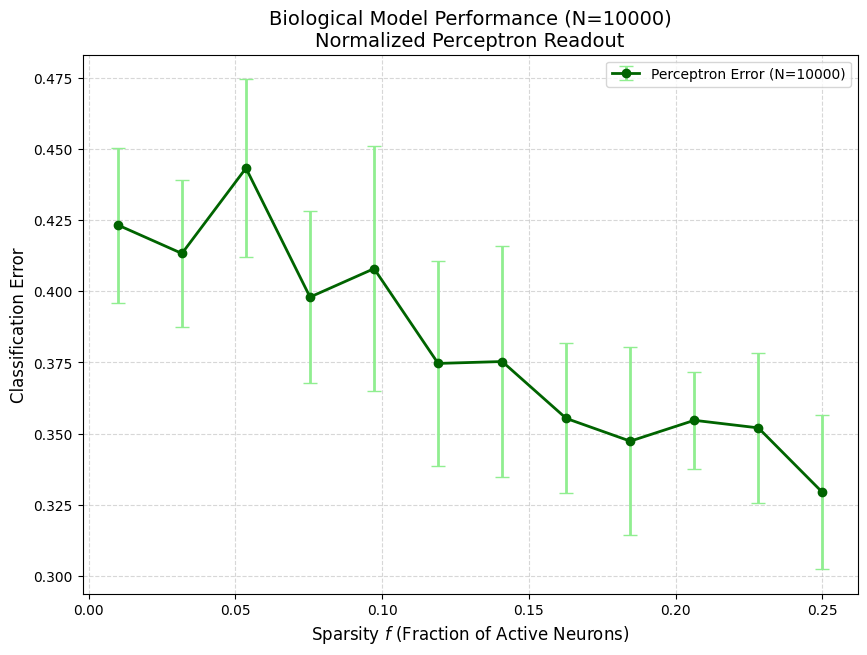

In [9]:
def run_biological_experiment():
    # --- Configuration ---
    N_NEURONS = 10000      # Increased Size
    N_SAMPLES = 1000      
    INPUT_DIM = 1000
    N_TRIALS = 5          
    
    # Sweep sparsity
    target_sparsities = np.linspace(0.01, 0.25, 12)
    
    mean_errors = []
    std_errors = []
    
    print(f"Simulating N={N_NEURONS} with Perceptron (Normalized Readout)...")

    for target_f in target_sparsities:
        trial_errors = []
        
        for _ in range(N_TRIALS):
            # 1. Generate Data
            X, y = make_classification(n_samples=N_SAMPLES, n_features=INPUT_DIM, 
                                       n_informative=20, n_redundant=5, 
                                       class_sep=1.5, flip_y=0.01) # Improved separation slightly
            
            # Input Scaling
            scaler_in = StandardScaler()
            X = scaler_in.fit_transform(X)
            
            # Positive Input Weights
            W_in = np.abs(np.random.randn(INPUT_DIM, N_NEURONS))
            
            H_S_all = X @ W_in
            H_train, H_test, y_train, y_test = train_test_split(H_S_all, y, test_size=0.3)
            
            # 2. Initialize Model
            rc = BiologicalRCModel(N_NEURONS, g=1.5) # Higher g for separation
            
            # 3. Tune Bias (Online)
            rc.tune_bias(H_train[:300], target_f)
            
            # 4. Run Dynamics
            X_rc_train = rc.dynamics(H_train)
            X_rc_test = rc.dynamics(H_test)
            
            # --- CRITICAL FIX: Normalize Reservoir States ---
            # This keeps the vector radius R small, allowing Perceptron to converge
            # regardless of how large N_NEURONS becomes.
            scaler_out = StandardScaler()
            X_rc_train = scaler_out.fit_transform(X_rc_train)
            X_rc_test = scaler_out.transform(X_rc_test)
            
            # 5. Train Readout (Increased iterations)
            # We assume the problem is linearly separable in high dims.
            # If not, Perceptron oscillates. 'tol' helps it stop if stuck.
            clf = Perceptron(max_iter=5000, tol=1e-4, random_state=42)
            clf.fit(X_rc_train, y_train)
            
            # 6. Measure Error
            err = 1.0 - clf.score(X_rc_test, y_test)
            trial_errors.append(err)
            
        mean_errors.append(np.mean(trial_errors))
        std_errors.append(np.std(trial_errors))
        print(f"f={target_f:.2f} | Error={mean_errors[-1]:.3f}")

    # --- Plotting ---
    plt.figure(figsize=(10, 7))
    plt.errorbar(target_sparsities, mean_errors, yerr=std_errors, 
                 fmt='-o', color='darkgreen', ecolor='lightgreen', 
                 capsize=5, linewidth=2, label=f'Perceptron Error (N={N_NEURONS})')
    
    plt.title(f'Biological Model Performance (N={N_NEURONS})\nNormalized Perceptron Readout', fontsize=14)
    plt.xlabel('Sparsity $f$ (Fraction of Active Neurons)', fontsize=12)
    plt.ylabel('Classification Error', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()
    plt.show()
if __name__ == "__main__":
    run_biological_experiment()

In [8]:
def run_biological_experiment():
    # --- Configuration ---
    N_NEURONS = 2000      # Large Reservoir
    N_SAMPLES = 1000      # Sample size
    INPUT_DIM = 40
    N_TRIALS = 5          
    
    # Sweep sparsity
    target_sparsities = np.linspace(0.01, 0.25, 12)
    
    mean_errors = []
    std_errors = []
    
    print(f"Simulating N={N_NEURONS} with L2-Regularized Perceptron...")

    for target_f in target_sparsities:
        trial_errors = []
        
        for _ in range(N_TRIALS):
            # 1. Generate Data
            # Note: flip_y introduces NOISE. High N will memorize this noise if not regularized.
            X, y = make_classification(n_samples=N_SAMPLES, n_features=INPUT_DIM, 
                                       n_informative=20, n_redundant=5, 
                                       class_sep=1.0, flip_y=0.05) 
            
            # CRITICAL: Scale Inputs
            scaler_in = StandardScaler()
            X = scaler_in.fit_transform(X)
            
            W_in = np.abs(np.random.randn(INPUT_DIM, N_NEURONS))
            H_S_all = X @ W_in
            H_train, H_test, y_train, y_test = train_test_split(H_S_all, y, test_size=0.3)
            
            # 2. Initialize Model
            rc = BiologicalRCModel(N_NEURONS, g=1.5)
            
            # 3. Tune Bias
            rc.tune_bias(H_train[:300], target_f)
            
            # 4. Run Dynamics
            X_rc_train = rc.dynamics(H_train)
            X_rc_test = rc.dynamics(H_test)
            
            # CRITICAL: Normalize Reservoir States
            scaler_out = StandardScaler()
            X_rc_train = scaler_out.fit_transform(X_rc_train)
            X_rc_test = scaler_out.transform(X_rc_test)
            
            # 5. Train Readout (Regularized)
            # penalty='l2': Prevents overfitting to noise in high dimensions
            # alpha=0.0001: Strength of regularization (tune if needed)
            clf = Perceptron(max_iter=5000, tol=1e-4, 
                             penalty='l2', alpha=0.0001,  # <--- THE FIX
                             random_state=None)
            clf.fit(X_rc_train, y_train)
            
            # 6. Measure Error
            err = 1.0 - clf.score(X_rc_test, y_test)
            trial_errors.append(err)
            
        mean_errors.append(np.mean(trial_errors))
        std_errors.append(np.std(trial_errors))
        print(f"f={target_f:.2f} | Error={mean_errors[-1]:.3f}")

    # --- Plotting ---
    plt.figure(figsize=(10, 7))
    plt.errorbar(target_sparsities, mean_errors, yerr=std_errors, 
                 fmt='-o', color='darkgreen', ecolor='lightgreen', 
                 capsize=5, linewidth=2, label=f'Perceptron (L2) Error (N={N_NEURONS})')
    
    plt.title(f'Biological Model Performance (N={N_NEURONS})\nL2-Regularized Perceptron', fontsize=14)
    plt.xlabel('Sparsity $f$ (Fraction of Active Neurons)', fontsize=12)
    plt.ylabel('Classification Error', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()
    plt.show()
if __name__ == "__main__":
    run_biological_experiment()

Simulating N=2000 with L2-Regularized Perceptron...
   [Tuning] Finding bias for target 0.01...
   [Converged] Bias: -27.93 | Activity: 0.000
   [Tuning] Finding bias for target 0.01...
   [Converged] Bias: -27.84 | Activity: 0.000
   [Tuning] Finding bias for target 0.01...
   [Converged] Bias: -27.84 | Activity: 0.000
   [Tuning] Finding bias for target 0.01...
   [Converged] Bias: -27.92 | Activity: 0.000
   [Tuning] Finding bias for target 0.01...
   [Converged] Bias: -27.75 | Activity: 0.000
f=0.01 | Error=0.502
   [Tuning] Finding bias for target 0.031818181818181815...


KeyboardInterrupt: 

## 7. Sparsity and Expansion Analysis

Simulation Start: P=100, N_S=100, f=0.1

--- Testing Reservoir Size N_R = 100 ---
   Epoch 0: Train Error 0.4800
   Epoch 10: Train Error 0.4500
   Epoch 20: Train Error 0.4000
   Epoch 30: Train Error 0.4500
   Epoch 40: Train Error 0.3500
   Epoch 0: Train Error 0.4700
   Epoch 10: Train Error 0.4400
   Epoch 20: Train Error 0.4400
   Epoch 30: Train Error 0.4200
   Epoch 40: Train Error 0.5300
   Epoch 0: Train Error 0.5200
   Epoch 10: Train Error 0.3800
   Epoch 20: Train Error 0.4100
   Epoch 30: Train Error 0.4100
   Epoch 40: Train Error 0.4800
   Epoch 0: Train Error 0.5600
   Epoch 10: Train Error 0.3600
   Epoch 20: Train Error 0.4200
   Epoch 30: Train Error 0.4100
   Epoch 40: Train Error 0.4600
   Epoch 0: Train Error 0.5100
   Epoch 10: Train Error 0.3900
   Epoch 20: Train Error 0.3800
   Epoch 30: Train Error 0.4000
   Epoch 40: Train Error 0.3800
   -> Mean Error: 0.3948

--- Testing Reservoir Size N_R = 500 ---
   Epoch 0: Train Error 0.5500
   Epoch 10: Train Error 

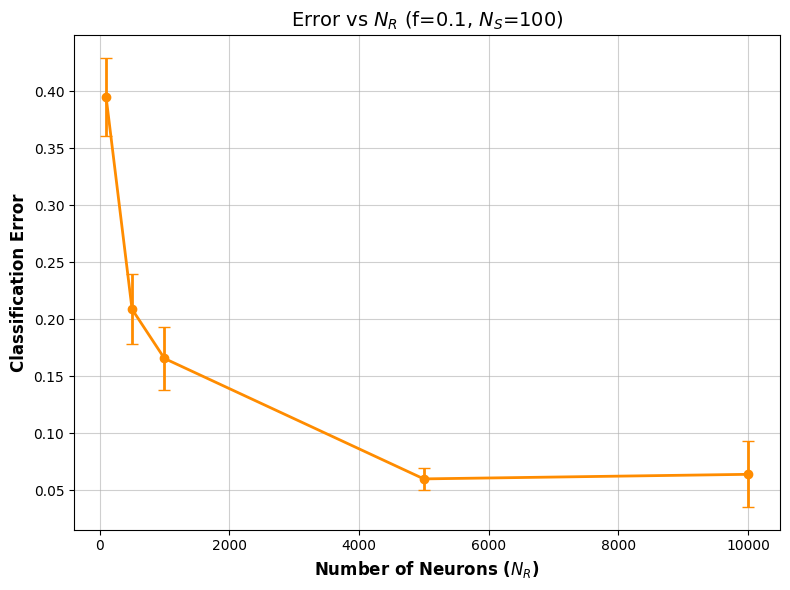

In [24]:
# Fixed Parameters
P = 100             
N_S = 100           # FIXED
f = 0.1              # FIXED
deltaS_learn = 0.1
deltaS_test = 0.2
eta = 0.01          

# Variable Parameters: Reservoir Size
# We test N_R from 500 to 5000
N_R_values = [100, 500, 1000, 5000, 10000, 15000, 20000]

# Reservoir Stability Params
g_rec_factor = 0.7  
g_input_factor = 2.0
mu_in = 2.0 / np.sqrt(N_S)          # Depends on N_S (Fixed)
sigma_in = g_input_factor / np.sqrt(N_S)

n_runs = 5 # Reduced slightly for speed, increase for smoother plots

all_results_mean = []
all_results_std = []

print(f"Simulation Start: P={P}, N_S={N_S}, f={f}")

for N_R in N_R_values:
    print(f"\n--- Testing Reservoir Size N_R = {N_R} ---")
    
    # RECALCULATE SCALING FACTORS dependent on N_R
    # (Important: normalization depends on 1/sqrt(N_R))
    mu_rec = -1.0 / np.sqrt(N_R)
    sigma_rec = g_rec_factor / np.sqrt(N_R)
    
    run_errors = []
    
    for r in range(n_runs):
        # 1. Generate Data
        labels = np.random.choice([-1, 1], size=P)
        central_patterns = generate_central_patterns(P, N_S)
        
        # 2. Generate Reservoir Matrices (New size N_R)
        J_in = np.random.normal(mu_in, sigma_in, (N_R, N_S)).astype(np.float32)
        J_rec = np.random.normal(mu_rec, sigma_rec, (N_R, N_R)).astype(np.float32)
        
        # 3. Train
        W, bias = train_perceptron_reservoir(
            central_patterns, labels, J_in, J_rec, f, 
            deltaS_learn=deltaS_learn, eta=eta
        )
        
        # 4. Test
        err = test_perceptron(W, bias, central_patterns, labels, J_in, J_rec, f, deltaS_test=deltaS_test)
        run_errors.append(err)
        
    all_results_mean.append(np.mean(run_errors))
    all_results_std.append(np.std(run_errors))
    print(f"   -> Mean Error: {np.mean(run_errors):.4f}")

# ==========================================
# 4. FINAL PLOT
# ==========================================
plt.figure(figsize=(8, 6))
plt.errorbar(
    N_R_values, all_results_mean, yerr=all_results_std,
    marker='o', lw=2, capsize=4, color='darkorange')

plt.xlabel("Number of Neurons ($N_R$)", fontsize=12, fontweight='bold')
plt.ylabel(f"Classification Error", fontsize=12, fontweight='bold')
plt.title(f"Error vs $N_R$ (f={f}, $N_S$={N_S})", fontsize=14)
plt.grid(True, which="both", ls="-", alpha=0.6)
plt.tight_layout()
plt.show()